# Phase F1 — self-contained Kaggle training

This notebook embeds the complete F1 runner. No separate trainer script is required. Attach only the private full `phase7_f1_train_v1` bundle and private Phase 5 validation bundle. The test set is never read.

Configuration: physical batch 2, accumulation 4, effective batch 8, validation batch 8, maximum 10 epochs, patience 3, learning rate 1e-5, weight decay 0.01, FP16 AMP training and FP32 validation.

In [ ]:
import importlib.metadata as md, subprocess, sys
PINS={'transformers':'4.57.1','tokenizers':'0.22.2','huggingface-hub':'0.36.2','safetensors':'0.8.0'}
installed={}
for p in PINS:
    try: installed[p]=md.version(p)
    except md.PackageNotFoundError: installed[p]=None
print('Installed:',installed)
if installed!=PINS:
    subprocess.run([sys.executable,'-m','pip','install','--no-cache-dir','--no-deps',*[f'{p}=={v}' for p,v in PINS.items()]],check=True)
    raise RuntimeError('Packages were pinned. Restart Kaggle and run all cells again.')
import tqdm; print('tqdm:',tqdm.__version__)


## Run the embedded trainer

The next cell performs input discovery, bundle verification, lazy feature extraction, FP16 training, batched validation, early stopping, and resumable checkpoint writing. tqdm bars show live progress. If a T4 OOM occurs, restart and change the declared physical batch to 1 with accumulation 8 in the embedded `main([])` call.

In [5]:
#!/usr/bin/env python3
"""Phase F1 full fine-tuning on the frozen Nyishi Narration split.

This is a private Kaggle runner. It starts from the pinned pretrained model,
uses lazy CPU feature extraction (no multi-gigabyte feature cache), trains with
FP16 AMP and gradient accumulation, validates with the Phase 6C-equivalent
batch-8 greedy policy, and saves resumable epoch checkpoints. It never reads
the test split.
"""
from __future__ import annotations

import argparse
import copy
import csv
import gc
import hashlib
import json
import math
import random
import re
import time
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import soundfile as sf
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import (
    GenerationConfig,
    WhisperForConditionalGeneration,
    WhisperProcessor,
    get_linear_schedule_with_warmup,
)


MODEL_ID = "neurlang/ipa-whisper-base"
MODEL_REVISION = "949f7c4e4ee374b5202bc5886f6e4552e5ae2371"
EOS_ID = 50257
MAX_LENGTH = 448
EXPECTED_TRAIN = 3629
EXPECTED_VALIDATION = 732
EXPECTED_REFERENCE_CODEPOINTS = 64137


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def safe(root: Path, relative: str) -> Path:
    path = (root / relative).resolve()
    path.relative_to(root.resolve())
    return path


def extract_bundle(archive: Path, bundle_type: str, destination: Path) -> tuple[Path, dict]:
    if archive.is_dir():
        marker = archive / "bundle_record.json"
        return archive, json.loads(marker.read_text())
    with zipfile.ZipFile(archive) as zf:
        markers = [n for n in zf.namelist() if n.endswith("bundle_record.json")]
        matches = [(n, json.loads(zf.read(n))) for n in markers]
        matches = [(n, r) for n, r in matches if r.get("bundle_type") == bundle_type]
        assert len(matches) == 1, f"Expected one {bundle_type} marker in {archive}"
        marker_name, record = matches[0]
        root = destination / bundle_type
        root.mkdir(parents=True, exist_ok=True)
        for member in tqdm(zf.infolist(), desc=f"Extracting {bundle_type}", unit="file"):
            target = (root / member.filename).resolve()
            target.relative_to(root.resolve())
        for member in tqdm(zf.infolist(), desc=f"Writing {bundle_type}", unit="file"):
            zf.extract(member, root)
        return (root / Path(marker_name).parent).resolve(), record


def discover_bundle(root: Path, bundle_type: str) -> Path:
    candidates = []
    for marker in root.rglob("bundle_record.json"):
        try:
            if json.loads(marker.read_text()).get("bundle_type") == bundle_type:
                candidates.append(marker.parent)
        except (OSError, json.JSONDecodeError):
            pass
    for archive in root.rglob("*.zip"):
        try:
            with zipfile.ZipFile(archive) as zf:
                for name in zf.namelist():
                    if name.endswith("bundle_record.json") and json.loads(zf.read(name)).get("bundle_type") == bundle_type:
                        candidates.append(archive)
        except (OSError, zipfile.BadZipFile, json.JSONDecodeError):
            pass
    candidates = sorted(set(candidates))
    assert len(candidates) == 1, f"Expected one {bundle_type} input, found {len(candidates)}: {candidates}"
    return candidates[0]


def verify_bundle(root: Path, record: dict, expected_partition: str) -> None:
    sums = root / "SHA256SUMS.txt"
    if sums.exists():
        entries = [line.split("  ", 1) for line in sums.read_text().splitlines() if line]
        for expected, relative in tqdm(entries, desc="Verifying bundle checksums", unit="file"):
            assert sha256(safe(root, relative)) == expected, f"Checksum failed: {relative}"
    # Validation bundles declare evaluation_partition/contains_test_audio;
    # the full F1 training bundle declares contains_validation_or_test_audio.
    # Accept either explicit schema without weakening the split checks.
    if "evaluation_partition" in record:
        assert record["evaluation_partition"] == expected_partition
    if "contains_test_audio" in record:
        assert record["contains_test_audio"] is False
    if "contains_validation_or_test_audio" in record:
        assert record["contains_validation_or_test_audio"] is False


def normalize(value: str) -> str:
    return re.sub(r" {2,}", " ", unicodedata.normalize("NFD", str(value)).strip())


def edit_counts(reference: str, hypothesis: str) -> tuple[int, int, int]:
    ref, hyp = list(reference), list(hypothesis)
    distance = [[0] * (len(hyp) + 1) for _ in range(len(ref) + 1)]
    for i in range(len(ref) + 1):
        distance[i][0] = i
    for j in range(len(hyp) + 1):
        distance[0][j] = j
    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):
            distance[i][j] = min(
                distance[i - 1][j] + 1,
                distance[i][j - 1] + 1,
                distance[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]),
            )
    substitutions = deletions = insertions = 0
    i, j = len(ref), len(hyp)
    while i or j:
        if i and j and ref[i - 1] == hyp[j - 1] and distance[i][j] == distance[i - 1][j - 1]:
            i, j = i - 1, j - 1
        elif i and j and distance[i][j] == distance[i - 1][j - 1] + 1:
            substitutions += 1; i, j = i - 1, j - 1
        elif i and distance[i][j] == distance[i - 1][j] + 1:
            deletions += 1; i -= 1
        else:
            insertions += 1; j -= 1
    return substitutions, deletions, insertions


def main(argv: list[str] | None = None) -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train-input", type=Path)
    parser.add_argument("--validation-input", type=Path)
    parser.add_argument("--output", type=Path, default=Path("/kaggle/working/phase7_F1_private"))
    parser.add_argument("--resume", type=Path, default=None, help="epoch_N directory from this exact F1 run")
    parser.add_argument("--physical-batch", type=int, default=2)
    parser.add_argument("--accumulation", type=int, default=4)
    parser.add_argument("--validation-batch", type=int, default=8)
    parser.add_argument("--max-epochs", type=int, default=10)
    parser.add_argument("--patience", type=int, default=3)
    parser.add_argument("--learning-rate", type=float, default=1e-5)
    parser.add_argument("--weight-decay", type=float, default=0.01)
    parser.add_argument("--seed", type=int, default=0)
    args, unknown = parser.parse_known_args(argv)
    if argv is not None and unknown:
        raise ValueError(f"Unknown arguments: {unknown}")
    assert torch.cuda.is_available(), "A CUDA GPU is required."
    assert args.physical_batch * args.accumulation == 8
    assert args.validation_batch == 8
    input_root = Path("/kaggle/input")
    if args.train_input is None:
        args.train_input = discover_bundle(input_root, "phase7_f1_train_v1")
    if args.validation_input is None:
        args.validation_input = discover_bundle(input_root, "phase5_validation_baseline")
    args.output.mkdir(parents=True, exist_ok=True)
    extracted = args.output / "_extracted_inputs"
    train_root, train_record = extract_bundle(args.train_input, "phase7_f1_train_v1", extracted)
    val_root, val_record = extract_bundle(args.validation_input, "phase5_validation_baseline", extracted)
    verify_bundle(train_root, train_record, "train")
    verify_bundle(val_root, val_record, "validation")
    assert train_record["clips"] == EXPECTED_TRAIN and val_record["clips"] == EXPECTED_VALIDATION
    assert train_record.get("contains_validation_or_test_audio") is False

    with (train_root / "train_manifest.csv").open(newline="", encoding="utf-8") as stream:
        train_rows = list(csv.DictReader(stream))
    with (val_root / "validation_manifest.csv").open(newline="", encoding="utf-8") as stream:
        val_rows = list(csv.DictReader(stream))
    assert len(train_rows) == EXPECTED_TRAIN and len(val_rows) == EXPECTED_VALIDATION
    assert sum(len(normalize(row["reference"])) for row in val_rows) == EXPECTED_REFERENCE_CODEPOINTS
    assert {row["sample_id"] for row in train_rows}.isdisjoint({row["sample_id"] for row in val_rows})

    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed); torch.cuda.manual_seed_all(args.seed)
    processor = WhisperProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    generation_config = GenerationConfig.from_dict(json.loads((val_root / "generation_config.json").read_text()))
    # Phase 6C proved this effective runtime policy is equivalent to single-example decoding.
    generation_config.forced_decoder_ids = [[1, None], [2, 50359]]
    generation_config.suppress_tokens = []
    generation_config.do_sample = False
    generation_config.num_beams = 1
    generation_config.max_length = MAX_LENGTH
    generation_config.begin_suppress_tokens = [220, EOS_ID]
    generation_config.return_dict_in_generate = True
    assert generation_config.eos_token_id == EOS_ID and generation_config.max_length == MAX_LENGTH

    def read_audio(root: Path, row: dict) -> np.ndarray:
        path = safe(root, row["audio_file"])
        audio, sample_rate = sf.read(path, dtype="float32", always_2d=True)
        assert sample_rate == 16000 and audio.shape[1] == 1
        assert 0.5 <= len(audio) / sample_rate < 30
        return audio[:, 0]

    def make_features(root: Path, rows: list[dict]) -> torch.Tensor:
        audios = [read_audio(root, row) for row in rows]
        # Force Whisper's fixed 30-second window for batched inputs. Plain
        # padding=True pads only to the longest item in this batch and can
        # return a time axis different from the required 3,000 frames.
        features = processor.feature_extractor(
            audios,
            sampling_rate=16000,
            return_tensors="pt",
            padding="max_length",
            truncation=True,
            max_length=480000,
        ).input_features
        if features.ndim == 2:
            features = features.unsqueeze(0)
        assert features.ndim == 3 and features.shape[1] == 80, (
            f"Unexpected Whisper feature shape before window normalization: {tuple(features.shape)}"
        )
        # Defensive normalization for minor Transformers/feature-extractor
        # patch differences: the model contract is always 80 x 3000.
        if features.shape[-1] > 3000:
            features = features[..., :3000]
        elif features.shape[-1] < 3000:
            features = F.pad(features, (0, 3000 - features.shape[-1]))
        assert tuple(features.shape[1:]) == (80, 3000)
        assert torch.isfinite(features).all().item(), "Non-finite Whisper features"
        return features.to(dtype=torch.float32)

    def make_labels(rows: list[dict]) -> torch.Tensor:
        targets = []
        for row in rows:
            reference = normalize(row["reference"])
            ids = processor.tokenizer(reference, add_special_tokens=False).input_ids
            assert processor.tokenizer.decode(ids, skip_special_tokens=False) == reference
            assert len(ids) + 1 < MAX_LENGTH
            targets.append(ids + [EOS_ID])
        padded = processor.tokenizer.pad({"input_ids": targets}, padding=True, return_tensors="pt")
        labels = padded["input_ids"].masked_fill(padded["attention_mask"].ne(1), -100)
        for row_index, target in enumerate(targets):
            assert labels[row_index, len(target) - 1].item() == EOS_ID
        return labels

    device = torch.device("cuda:0")
    model_source = args.resume / "model" if args.resume else MODEL_ID
    model_kwargs = {"dtype": torch.float32, "attn_implementation": "sdpa"}
    if not args.resume:
        model_kwargs["revision"] = MODEL_REVISION
    model = WhisperForConditionalGeneration.from_pretrained(model_source, **model_kwargs).to(device).train()
    model.config.use_cache = False
    decay, no_decay = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            (no_decay if name.endswith("bias") or "layer_norm" in name.lower() else decay).append(parameter)
    optimizer = torch.optim.AdamW(
        [{"params": decay, "weight_decay": args.weight_decay}, {"params": no_decay, "weight_decay": 0.0}],
        lr=args.learning_rate,
    )
    micro_batches = math.ceil(len(train_rows) / args.physical_batch)
    steps_per_epoch = math.ceil(micro_batches / args.accumulation)
    total_steps = steps_per_epoch * args.max_epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, max(1, math.ceil(0.05 * total_steps)), total_steps)
    scaler = torch.amp.GradScaler("cuda", init_scale=256.0)
    fingerprint = hashlib.sha256(json.dumps({
        "model": MODEL_ID, "revision": MODEL_REVISION, "train": train_record.get("manifest_sha256"),
        "validation": val_record.get("manifest_sha256"), "seed": args.seed,
        "physical_batch": args.physical_batch, "accumulation": args.accumulation,
        "validation_batch": args.validation_batch, "max_epochs": args.max_epochs,
        "patience": args.patience, "learning_rate": args.learning_rate,
        "generation": generation_config.to_dict(),
    }, sort_keys=True, default=str).encode()).hexdigest()
    start_epoch = 0; completed_steps = 0; history = []; best_cer = float("inf"); best_epoch = None; stale_epochs = 0
    if args.resume:
        state = torch.load(args.resume / "training_state.pt", map_location="cpu", weights_only=False)
        assert state["fingerprint"] == fingerprint and state["epoch"] < args.max_epochs
        optimizer.load_state_dict(state["optimizer"]); scheduler.load_state_dict(state["scheduler"]); scaler.load_state_dict(state["scaler"])
        for item in optimizer.state.values():
            for key, value in item.items():
                if isinstance(value, torch.Tensor): item[key] = value.to(device)
        random.setstate(state["python_rng"]); np.random.set_state(state["numpy_rng"]); torch.set_rng_state(state["torch_rng"]); torch.cuda.set_rng_state_all(state["cuda_rng"])
        start_epoch = state["epoch"]; completed_steps = state["completed_steps"]; history = state["history"]; best_cer = state["best_cer"]; best_epoch = state["best_epoch"]; stale_epochs = state.get("stale_epochs", 0)
    print({"train_clips": len(train_rows), "validation_clips": len(val_rows), "steps_per_epoch": steps_per_epoch, "max_epochs": args.max_epochs, "patience": args.patience, "fingerprint": fingerprint})

    def evaluate(epoch: int) -> tuple[dict, list[dict]]:
        model.eval(); model.config.use_cache = True; records = []; started = time.perf_counter()
        for begin in tqdm(range(0, len(val_rows), args.validation_batch), desc=f"Epoch {epoch} validation", unit="batch"):
            rows = val_rows[begin:begin + args.validation_batch]
            features = make_features(val_root, rows).to(device)
            with torch.inference_mode():
                generated = model.generate(input_features=features, generation_config=copy.deepcopy(generation_config))
            for row, sequence in zip(rows, generated.sequences.detach().cpu().tolist()):
                ids = sequence[:sequence.index(EOS_ID) + 1] if EOS_ID in sequence else sequence[:MAX_LENGTH]
                raw = processor.tokenizer.decode(ids, skip_special_tokens=True); hypothesis = normalize(raw); reference = normalize(row["reference"])
                substitutions, deletions, insertions = edit_counts(reference, hypothesis)
                records.append({"sample_id": row["sample_id"], "reference": reference, "raw_prediction": raw, "normalized_prediction": hypothesis, "token_ids": ids, "eos": bool(ids and ids[-1] == EOS_ID), "cap_without_eos": len(ids) >= MAX_LENGTH and (not ids or ids[-1] != EOS_ID), "S": substitutions, "D": deletions, "I": insertions, "duration_seconds": float(row["duration_seconds"])})
            del features, generated
        model.train(); model.config.use_cache = False; gc.collect(); torch.cuda.empty_cache()
        reference_codepoints = sum(len(r["reference"]) for r in records); S = sum(r["S"] for r in records); D = sum(r["D"] for r in records); I = sum(r["I"] for r in records)
        return {"clips": len(records), "reference_codepoints": reference_codepoints, "S": S, "D": D, "I": I, "edit_count": S + D + I, "corpus_cer": (S + D + I) / reference_codepoints, "eos_count": sum(r["eos"] for r in records), "cap_without_eos": sum(r["cap_without_eos"] for r in records), "replacement_character_outputs": sum("�" in r["normalized_prediction"] for r in records), "elapsed_seconds": time.perf_counter() - started}, records

    run_started = time.perf_counter(); torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(start_epoch + 1, args.max_epochs + 1):
        model.train(); model.config.use_cache = False; indices = list(range(len(train_rows))); random.shuffle(indices); groups = [indices[i:i + args.physical_batch] for i in range(0, len(indices), args.physical_batch)]; losses = []; epoch_updates = 0; amp_retries = 0; epoch_started = time.perf_counter()
        for begin in tqdm(range(0, len(groups), args.accumulation), desc=f"Epoch {epoch} training", unit="update"):
            accumulation_groups = groups[begin:begin + args.accumulation]
            for attempt in range(8):
                optimizer.zero_grad(set_to_none=True); finite = True; group_losses = []
                try:
                    for group in accumulation_groups:
                        rows = [train_rows[i] for i in group]; features = make_features(train_root, rows).to(device); labels = make_labels(rows).to(device)
                        with torch.autocast(device_type="cuda", dtype=torch.float16): loss = model(input_features=features, labels=labels).loss
                        if not torch.isfinite(loss).item(): raise FloatingPointError("nonfinite forward loss")
                        group_losses.append(float(loss.detach())); scaler.scale(loss / len(accumulation_groups)).backward(); del features, labels
                    scaler.unscale_(optimizer); grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True, foreach=False); assert float(grad_norm) > 0
                    old_scale = scaler.get_scale(); scaler.step(optimizer); scaler.update()
                    if scaler.get_scale() < old_scale: amp_retries += 1; continue
                    scheduler.step(); completed_steps += 1; epoch_updates += 1; losses.extend(group_losses); break
                except torch.cuda.OutOfMemoryError as exc:
                    torch.cuda.empty_cache(); raise RuntimeError("CUDA OOM. Restart with --physical-batch 1 --accumulation 8; do not change the effective batch size.") from exc
            else: raise RuntimeError("No finite AMP update after eight attempts.")
        train_memory = torch.cuda.max_memory_allocated(device) / 1024**2
        validation, predictions = evaluate(epoch)
        improved = validation["corpus_cer"] < best_cer
        if improved: best_cer = validation["corpus_cer"]; best_epoch = epoch; stale_epochs = 0
        else: stale_epochs += 1
        record = {"epoch": epoch, "updates": epoch_updates, "cumulative_updates": completed_steps, "training_loss": sum(losses) / len(losses), "amp_retries": amp_retries, "train_peak_allocated_mib": train_memory, "epoch_seconds": time.perf_counter() - epoch_started, "validation": validation}
        history.append(record); checkpoint = args.output / f"epoch_{epoch:02d}"; checkpoint.mkdir(exist_ok=True); model.save_pretrained(checkpoint / "model", safe_serialization=True); torch.save({"fingerprint": fingerprint, "epoch": epoch, "completed_steps": completed_steps, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "python_rng": random.getstate(), "numpy_rng": np.random.get_state(), "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all(), "history": history, "best_cer": best_cer, "best_epoch": best_epoch, "stale_epochs": stale_epochs}, checkpoint / "training_state.pt")
        (args.output / f"validation_epoch_{epoch:02d}_private.jsonl").write_text("\n".join(json.dumps(p, ensure_ascii=False) for p in predictions) + "\n")
        (args.output / "aggregate_history.json").write_text(json.dumps(history, indent=2) + "\n")
        print({"epoch": epoch, "validation_cer_percent": 100 * validation["corpus_cer"], "best_epoch": best_epoch, "stale_epochs": stale_epochs, "train_peak_allocated_mib": train_memory, "validation_seconds": validation["elapsed_seconds"]})
        if stale_epochs >= args.patience: print(f"Early stopping after {args.patience} non-improving validation epochs."); break
    report = {"experiment": "F1", "status": "complete", "model_id": MODEL_ID, "model_revision": MODEL_REVISION, "train_clips": len(train_rows), "train_hours": train_record["hours"], "validation_clips": len(val_rows), "validation_hours": val_record["hours"], "test_data_used": False, "seed": args.seed, "physical_batch": args.physical_batch, "accumulation": args.accumulation, "effective_batch": 8, "validation_batch": args.validation_batch, "learning_rate": args.learning_rate, "weight_decay": args.weight_decay, "max_epochs": args.max_epochs, "patience": args.patience, "best_epoch": best_epoch, "best_validation_cer": best_cer, "completed_steps": completed_steps, "total_wall_seconds": time.perf_counter() - run_started, "peak_allocated_mib": torch.cuda.max_memory_allocated(device) / 1024**2, "peak_reserved_mib": torch.cuda.max_memory_reserved(device) / 1024**2, "history": history}
    (args.output / "F1_report_private.json").write_text(json.dumps(report, indent=2) + "\n"); print("F1 complete; best epoch", best_epoch, "CER", 100 * best_cer)



# Start the embedded runner with explicit notebook-safe arguments.
main([])


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

{'train_clips': 3629, 'validation_clips': 732, 'steps_per_epoch': 454, 'max_epochs': 10, 'patience': 3, 'fingerprint': '87444c628248576b58927d17eb43b94adc5c8abf9fe7fde30cd9c036c6ba4250'}


Epoch 1 training:   0%|          | 0/454 [00:00<?, ?update/s]

You're using a WhisperTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Epoch 1 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

... (4 outputs left out)

{'epoch': 2, 'validation_cer_percent': 55.746293091351326, 'best_epoch': 2, 'stale_epochs': 0, 'train_peak_allocated_mib': 2735.07666015625, 'validation_seconds': 199.51773286900016}


Epoch 3 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 3 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [7]:
from pathlib import Path

# Find the latest complete epoch checkpoint.
out = Path("/kaggle/working/phase7_F1_private")

checkpoints = sorted(
    p for p in out.glob("epoch_*")
    if (p / "training_state.pt").is_file()
    and (p / "model" / "config.json").is_file()
)

if not checkpoints:
    print("No completed epoch checkpoint found.")
    print("The run must restart from Epoch 1.")
    main([
        "--output", str(out),
        "--physical-batch", "2",
        "--accumulation", "4",
        "--validation-batch", "8",
        "--max-epochs", "10",
        "--patience", "3",
        "--learning-rate", "1e-5",
        "--weight-decay", "0.01",
    ])
else:
    latest = checkpoints[-1]
    print("Resuming from:", latest)

    main([
        "--output", str(out),
        "--resume", str(latest),
        "--physical-batch", "2",
        "--accumulation", "4",
        "--validation-batch", "8",
        "--max-epochs", "10",
        "--patience", "3",
        "--learning-rate", "1e-5",
        "--weight-decay", "0.01",
    ])

Resuming from: /kaggle/working/phase7_F1_private/epoch_02


Verifying bundle checksums:   0%|          | 0/3631 [00:00<?, ?file/s]

Verifying bundle checksums:   0%|          | 0/737 [00:00<?, ?file/s]

{'train_clips': 3629, 'validation_clips': 732, 'steps_per_epoch': 454, 'max_epochs': 10, 'patience': 3, 'fingerprint': '87444c628248576b58927d17eb43b94adc5c8abf9fe7fde30cd9c036c6ba4250'}


Epoch 3 training:   0%|          | 0/454 [00:00<?, ?update/s]

You're using a WhisperTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


... (7 outputs left out)

{'epoch': 5, 'validation_cer_percent': 51.50693047694779, 'best_epoch': 3, 'stale_epochs': 2, 'train_peak_allocated_mib': 3558.43017578125, 'validation_seconds': 189.50839477299996}


Epoch 6 training:   0%|          | 0/454 [00:00<?, ?update/s]

Epoch 6 validation:   0%|          | 0/92 [00:00<?, ?batch/s]

{'epoch': 6, 'validation_cer_percent': 55.484353805135875, 'best_epoch': 3, 'stale_epochs': 3, 'train_peak_allocated_mib': 3558.43017578125, 'validation_seconds': 198.10382165300007}
Early stopping after 3 non-improving validation epochs.
F1 complete; best epoch 3 CER 51.346336747899024


## Outputs

Private outputs are written to `/kaggle/working/phase7_F1_private/`: epoch checkpoints, resumable state, aggregate history, private validation predictions, and `F1_report_private.json`. Do not publish these files.

In [8]:
from pathlib import Path
import json, os

OUT = Path("/kaggle/working/phase7_F1_private")
REPORT_PATH = OUT / "F1_report_private.json"

assert REPORT_PATH.is_file(), "F1_report_private.json not found. Finish training first."

report = json.loads(REPORT_PATH.read_text())
history = report["history"]

assert report["status"] == "complete"
assert report["test_data_used"] is False

print("F1 status:", report["status"])
print("Train clips:", report["train_clips"])
print("Validation clips:", report["validation_clips"])
print("Best epoch:", report["best_epoch"])
print("Best validation CER:", 100 * report["best_validation_cer"], "%")
print("Total runtime:", round(report["total_wall_seconds"] / 60, 2), "minutes")
print("Peak GPU memory:", round(report["peak_allocated_mib"], 1), "MiB")
print("Test data used:", report["test_data_used"])

print("\nOutput files:")
for path in sorted(OUT.rglob("*")):
    if path.is_file() and "_extracted_inputs" not in path.parts:
        print(f"{path.relative_to(OUT)} — {path.stat().st_size / 1024**2:.2f} MiB")

F1 status: complete
Train clips: 3629
Validation clips: 732
Best epoch: 3
Best validation CER: 51.346336747899024 %
Total runtime: 25.48 minutes
Peak GPU memory: 3558.4 MiB
Test data used: False

Output files:
F1_report_private.json — 0.00 MiB
aggregate_history.json — 0.00 MiB
epoch_01/model/config.json — 0.00 MiB
epoch_01/model/generation_config.json — 0.00 MiB
epoch_01/model/model.safetensors — 276.95 MiB
epoch_01/training_state.pt — 548.20 MiB
epoch_02/model/config.json — 0.00 MiB
epoch_02/model/generation_config.json — 0.00 MiB
epoch_02/model/model.safetensors — 276.95 MiB
epoch_02/training_state.pt — 548.20 MiB
epoch_03/model/config.json — 0.00 MiB
epoch_03/model/generation_config.json — 0.00 MiB
epoch_03/model/model.safetensors — 276.95 MiB
epoch_03/training_state.pt — 548.21 MiB
epoch_04/model/config.json — 0.00 MiB
epoch_04/model/generation_config.json — 0.00 MiB
epoch_04/model/model.safetensors — 276.95 MiB
epoch_04/training_state.pt — 548.21 MiB
epoch_05/model/config.json — 0

In [9]:
import hashlib
import zipfile
from tqdm.auto import tqdm
from IPython.display import FileLink, display

best_epoch = int(report["best_epoch"])
best_checkpoint = OUT / f"epoch_{best_epoch:02d}"

assert best_checkpoint.is_dir()
assert (best_checkpoint / "model" / "config.json").is_file()
assert (best_checkpoint / "training_state.pt").is_file()

# Private results ZIP: report, history, plots, and validation predictions.
result_zip = Path("/kaggle/working/phase7_F1_results_private.zip")

result_files = [
    REPORT_PATH,
    OUT / "aggregate_history.json",
]

result_files += sorted((OUT / "plots").glob("*")) if (OUT / "plots").is_dir() else []
result_files += sorted(OUT.glob("validation_epoch_*_private.jsonl"))

result_files = [
    p for p in result_files
    if p.is_file() and "_extracted_inputs" not in p.parts
]

checksums = []

with zipfile.ZipFile(
    result_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True,
) as zf:
    for path in tqdm(result_files, desc="Zipping private F1 results", unit="file"):
        archive_name = f"phase7_F1_results/{path.relative_to(OUT).as_posix()}"
        zf.write(path, archive_name)

        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        checksums.append(f"{digest}  {archive_name}")

    zf.writestr(
        "phase7_F1_results/SHA256SUMS.txt",
        "\n".join(checksums) + "\n",
    )

with zipfile.ZipFile(result_zip) as zf:
    assert zf.testzip() is None

# Separate best-checkpoint ZIP.
checkpoint_zip = Path("/kaggle/working/phase7_F1_best_checkpoint_private.zip")

checkpoint_files = sorted(
    p for p in best_checkpoint.rglob("*")
    if p.is_file()
)

with zipfile.ZipFile(
    checkpoint_zip,
    "w",
    compression=zipfile.ZIP_STORED,
    allowZip64=True,
) as zf:
    for path in tqdm(
        checkpoint_files,
        desc="Zipping best checkpoint",
        unit="file",
    ):
        archive_name = (
            f"phase7_F1_best_checkpoint/"
            f"{path.relative_to(best_checkpoint).as_posix()}"
        )
        zf.write(path, archive_name)

with zipfile.ZipFile(checkpoint_zip) as zf:
    assert zf.testzip() is None

print("Results ZIP:")
print(result_zip, round(result_zip.stat().st_size / 1024**2, 2), "MiB")
print("Checkpoint ZIP:")
print(checkpoint_zip, round(checkpoint_zip.stat().st_size / 1024**2, 2), "MiB")

display(FileLink(str(result_zip)))
display(FileLink(str(checkpoint_zip)))


Zipping private F1 results:   0%|          | 0/8 [00:00<?, ?file/s]

Zipping best checkpoint:   0%|          | 0/4 [00:00<?, ?file/s]

Results ZIP:
/kaggle/working/phase7_F1_results_private.zip 0.9 MiB
Checkpoint ZIP:
/kaggle/working/phase7_F1_best_checkpoint_private.zip 825.16 MiB


/kaggle/working/phase7_F1_results_private.zip

/kaggle/working/phase7_F1_best_checkpoint_private.zip

Best epoch: 3
Final completed epoch: 6
Test data used: False


,epoch,training_loss,validation_CER_%,S,D,I,EOS_count,cap_without_EOS,U+FFFD,epoch_minutes,validation_minutes,train_peak_MiB
0,1,2.439,60.071,17056,3973,17499,726,6,1,6.714,3.572,2735.077
1,2,1.193,55.746,15822,4711,15221,730,2,1,6.346,3.325,2735.077
2,3,0.927,51.346,15940,4323,12669,730,2,0,6.239,3.154,3558.430
3,4,0.762,56.184,16518,5024,14493,726,6,2,6.631,3.539,3558.430
4,5,0.613,51.507,15677,4617,12741,732,0,0,6.201,3.158,3558.430
5,6,0.506,55.484,16502,5191,13893,729,3,2,6.339,3.302,3558.430


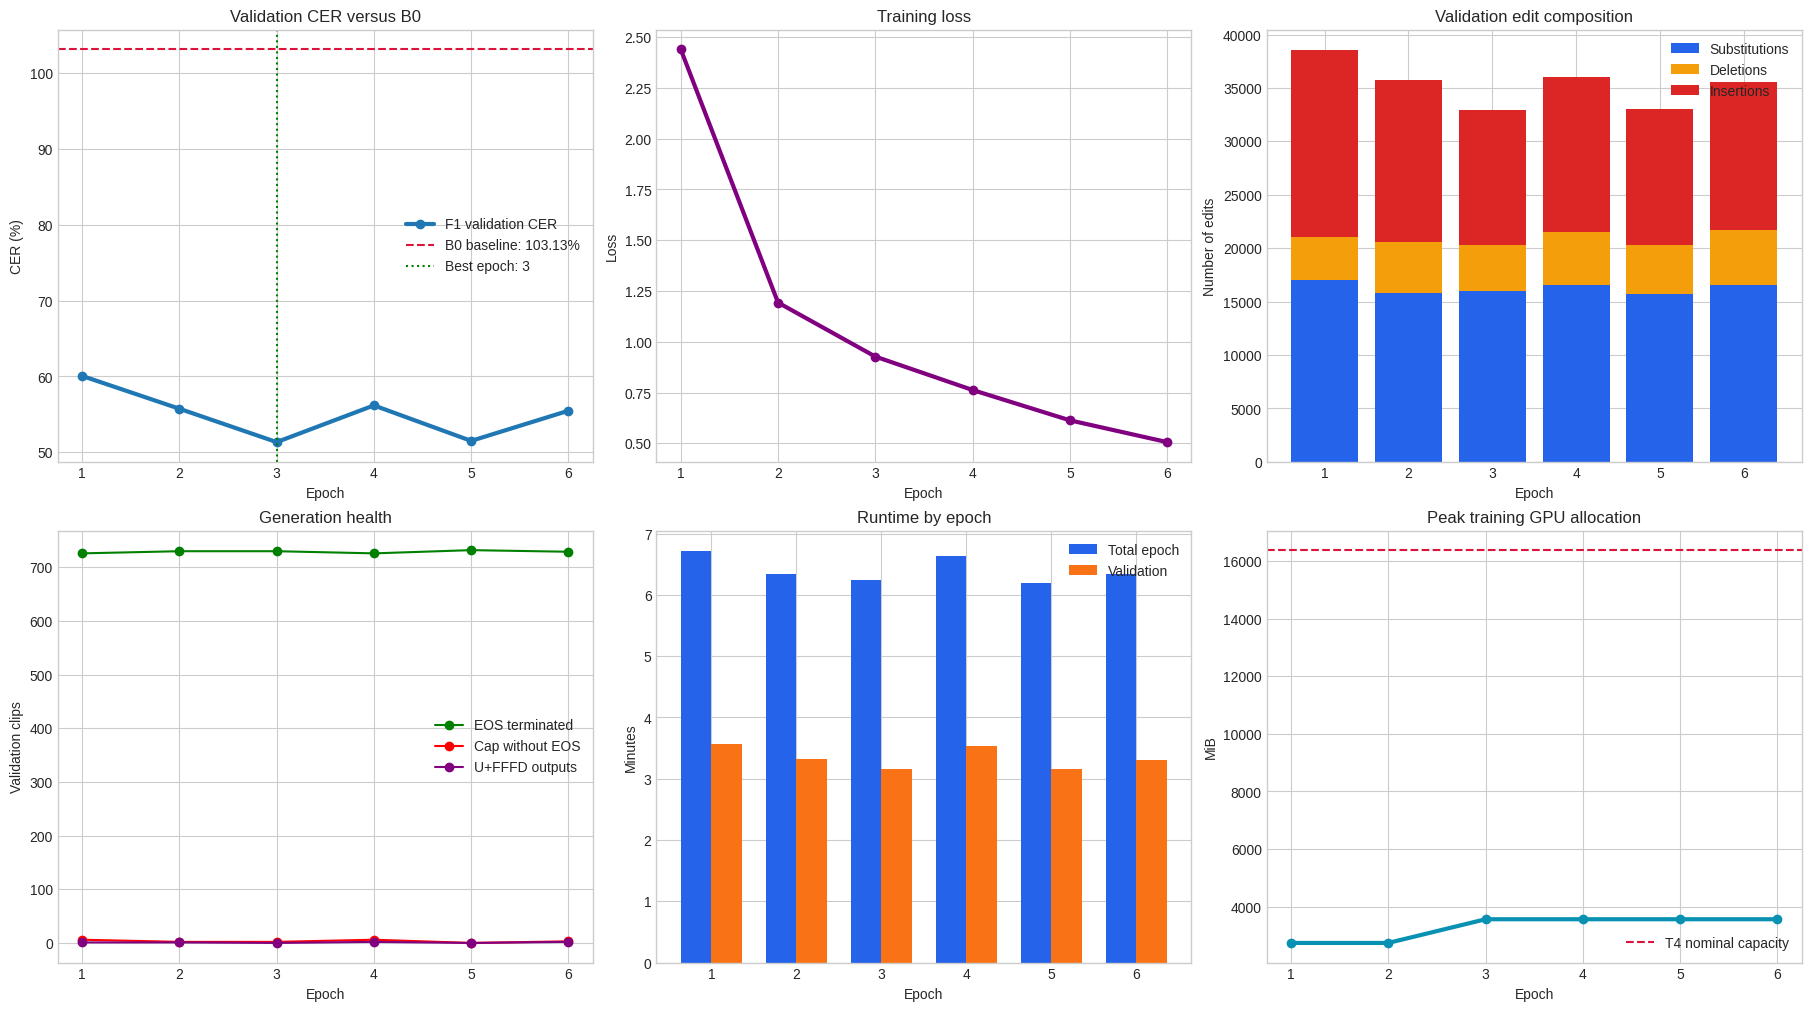

Saved aggregate metrics to: /kaggle/working/phase7_F1_private/plots


In [11]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the completed private F1 output directory.
OUT = Path("/kaggle/working/phase7_F1_private")
REPORT_PATH = OUT / "F1_report_private.json"

assert REPORT_PATH.is_file(), (
    "F1_report_private.json was not found. "
    "Finish training or attach the saved F1 output directory."
)

# Load the saved aggregate report; this does not run model inference.
report = json.loads(REPORT_PATH.read_text())
history = report["history"]

assert report["status"] == "complete"
assert report["test_data_used"] is False

# Rebuild the epoch table every time this cell runs.
rows = []

for item in history:
    validation = item["validation"]

    rows.append({
        "epoch": item["epoch"],
        "training_loss": item["training_loss"],
        "validation_CER_%": 100 * validation["corpus_cer"],
        "S": validation["S"],
        "D": validation["D"],
        "I": validation["I"],
        "EOS_count": validation["eos_count"],
        "cap_without_EOS": validation["cap_without_eos"],
        "U+FFFD": validation["replacement_character_outputs"],
        "epoch_minutes": item["epoch_seconds"] / 60,
        "validation_minutes": validation["elapsed_seconds"] / 60,
        "train_peak_MiB": item["train_peak_allocated_mib"],
    })

epoch_table = pd.DataFrame(rows)

# Identify best and final epochs.
best_epoch = int(report["best_epoch"])
final_epoch = int(epoch_table["epoch"].max())

print("Best epoch:", best_epoch)
print("Final completed epoch:", final_epoch)
print("Test data used:", report["test_data_used"])

display(epoch_table.round(3))

# Prepare plotting arrays.
epochs = epoch_table["epoch"].to_numpy()
cer = epoch_table["validation_CER_%"].to_numpy()
loss = epoch_table["training_loss"].to_numpy()
B0_CER = 103.1292389728238

# Create the aggregate diagnostic figure.
plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10),
    constrained_layout=True,
)

# Validation CER versus B0.
axes[0, 0].plot(
    epochs,
    cer,
    "o-",
    linewidth=3,
    label="F1 validation CER",
)

axes[0, 0].axhline(
    B0_CER,
    linestyle="--",
    color="crimson",
    label=f"B0 baseline: {B0_CER:.2f}%",
)

axes[0, 0].axvline(
    best_epoch,
    linestyle=":",
    color="green",
    label=f"Best epoch: {best_epoch}",
)

axes[0, 0].set_title("Validation CER versus B0")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("CER (%)")
axes[0, 0].legend()

# Training loss.
axes[0, 1].plot(
    epochs,
    loss,
    "o-",
    linewidth=3,
    color="purple",
)

axes[0, 1].set_title("Training loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")

# Error composition.
bottom = np.zeros(len(epoch_table))

for key, color, label in [
    ("S", "#2563eb", "Substitutions"),
    ("D", "#f59e0b", "Deletions"),
    ("I", "#dc2626", "Insertions"),
]:
    values = epoch_table[key].to_numpy()

    axes[0, 2].bar(
        epochs,
        values,
        bottom=bottom,
        color=color,
        label=label,
    )

    bottom += values

axes[0, 2].set_title("Validation edit composition")
axes[0, 2].set_xlabel("Epoch")
axes[0, 2].set_ylabel("Number of edits")
axes[0, 2].legend()

# Generation health.
axes[1, 0].plot(
    epochs,
    epoch_table["EOS_count"],
    "o-",
    color="green",
    label="EOS terminated",
)

axes[1, 0].plot(
    epochs,
    epoch_table["cap_without_EOS"],
    "o-",
    color="red",
    label="Cap without EOS",
)

axes[1, 0].plot(
    epochs,
    epoch_table["U+FFFD"],
    "o-",
    color="purple",
    label="U+FFFD outputs",
)

axes[1, 0].set_title("Generation health")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Validation clips")
axes[1, 0].legend()

# Runtime.
axes[1, 1].bar(
    epochs - 0.18,
    epoch_table["epoch_minutes"],
    width=0.36,
    color="#2563eb",
    label="Total epoch",
)

axes[1, 1].bar(
    epochs + 0.18,
    epoch_table["validation_minutes"],
    width=0.36,
    color="#f97316",
    label="Validation",
)

axes[1, 1].set_title("Runtime by epoch")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Minutes")
axes[1, 1].legend()

# GPU memory.
axes[1, 2].plot(
    epochs,
    epoch_table["train_peak_MiB"],
    "o-",
    linewidth=3,
    color="#0891b2",
)

axes[1, 2].axhline(
    16 * 1024,
    linestyle="--",
    color="crimson",
    label="T4 nominal capacity",
)

axes[1, 2].set_title("Peak training GPU allocation")
axes[1, 2].set_xlabel("Epoch")
axes[1, 2].set_ylabel("MiB")
axes[1, 2].legend()

for axis in axes.flat:
    axis.set_xticks(epochs)

plt.show()

# Save aggregate data for later reuse.
plot_dir = OUT / "plots"
plot_dir.mkdir(exist_ok=True)

epoch_table.to_csv(
    plot_dir / "f1_epoch_aggregate_metrics.csv",
    index=False,
)

print("Saved aggregate metrics to:", plot_dir)

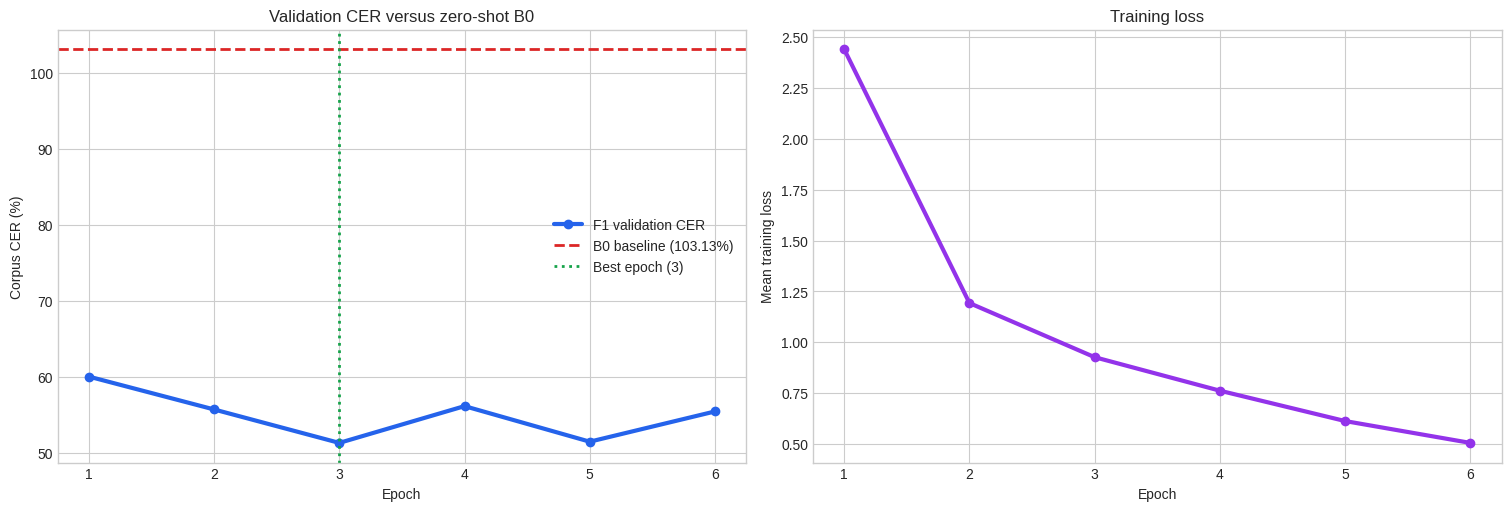

In [12]:
import matplotlib.pyplot as plt
import numpy as np

epochs = epoch_table["epoch"].to_numpy()
cer = epoch_table["validation_CER_%"].to_numpy()
loss = epoch_table["training_loss"].to_numpy()

B0_CER = 103.1292389728238
best_epoch = int(report["best_epoch"])

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

axes[0].plot(
    epochs,
    cer,
    marker="o",
    linewidth=3,
    color="#2563eb",
    label="F1 validation CER",
)
axes[0].axhline(
    B0_CER,
    linestyle="--",
    linewidth=2,
    color="#dc2626",
    label=f"B0 baseline ({B0_CER:.2f}%)",
)
axes[0].axvline(
    best_epoch,
    linestyle=":",
    linewidth=2,
    color="#16a34a",
    label=f"Best epoch ({best_epoch})",
)
axes[0].set_title("Validation CER versus zero-shot B0")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Corpus CER (%)")
axes[0].legend()

axes[1].plot(
    epochs,
    loss,
    marker="o",
    linewidth=3,
    color="#9333ea",
)
axes[1].set_title("Training loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean training loss")

for ax in axes:
    ax.set_xticks(epochs)

plt.show()

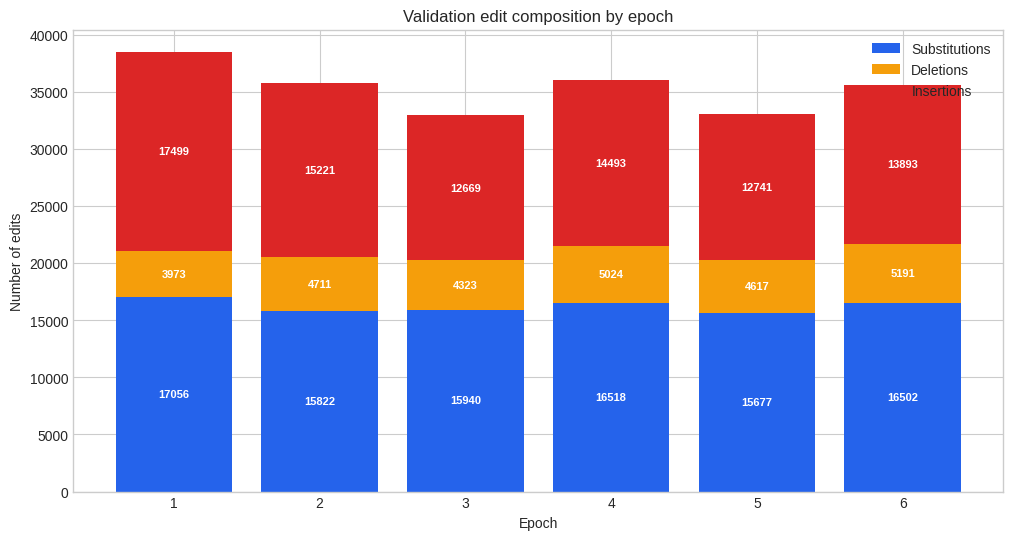

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))

bottom = np.zeros(len(epoch_table))

colors = {
    "S": "#2563eb",
    "D": "#f59e0b",
    "I": "#dc2626",
}

labels = {
    "S": "Substitutions",
    "D": "Deletions",
    "I": "Insertions",
}

for key in ["S", "D", "I"]:
    values = epoch_table[key].to_numpy()

    ax.bar(
        epochs,
        values,
        bottom=bottom,
        color=colors[key],
        label=labels[key],
    )

    for x, base, value in zip(epochs, bottom, values):
        ax.text(
            x,
            base + value / 2,
            str(int(value)),
            ha="center",
            va="center",
            fontsize=8,
            color="white",
            fontweight="bold",
        )

    bottom += values

ax.set_title("Validation edit composition by epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("Number of edits")
ax.set_xticks(epochs)
ax.legend()

plt.show()

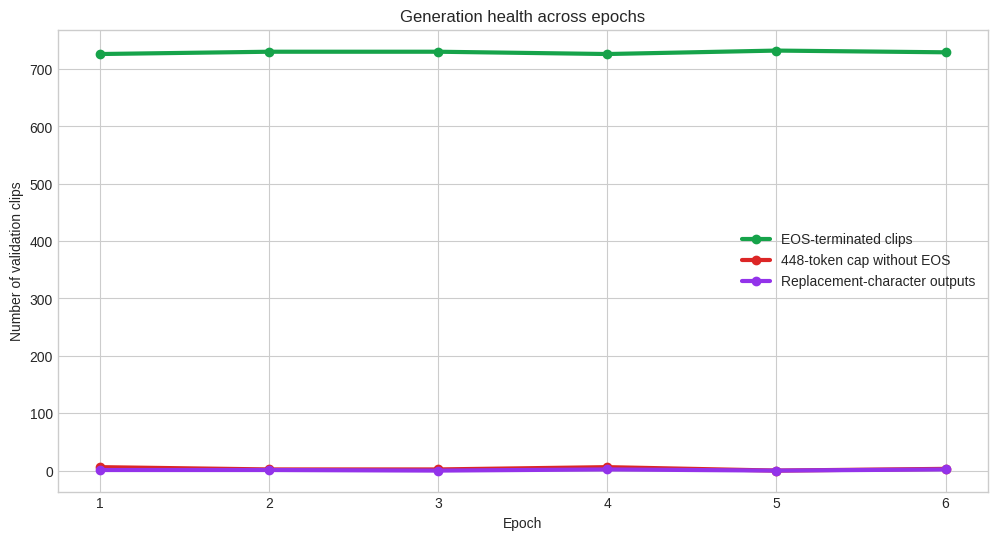

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))

diagnostic_columns = [
    ("EOS_count", "EOS-terminated clips", "#16a34a"),
    ("cap_without_EOS", "448-token cap without EOS", "#dc2626"),
    ("U+FFFD", "Replacement-character outputs", "#9333ea"),
]

for column, label, color in diagnostic_columns:
    ax.plot(
        epochs,
        epoch_table[column],
        marker="o",
        linewidth=3,
        label=label,
        color=color,
    )

ax.set_title("Generation health across epochs")
ax.set_xlabel("Epoch")
ax.set_ylabel("Number of validation clips")
ax.set_xticks(epochs)
ax.legend()

plt.show()

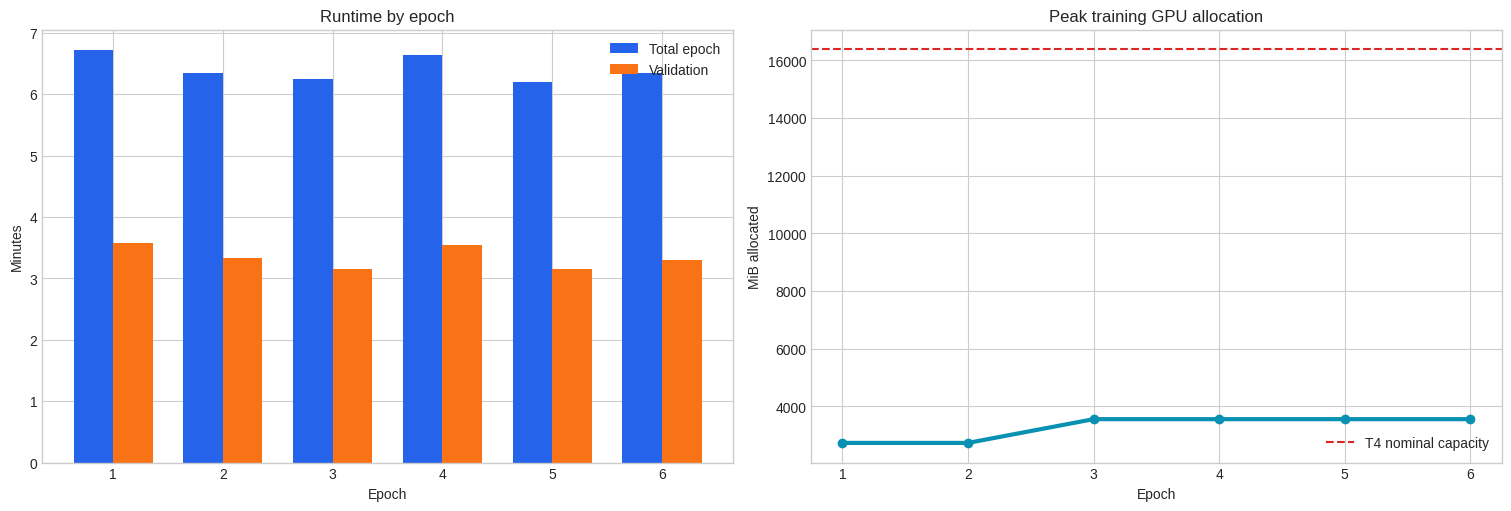

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

axes[0].bar(
    epochs - 0.18,
    epoch_table["epoch_minutes"],
    width=0.36,
    label="Total epoch",
    color="#2563eb",
)

axes[0].bar(
    epochs + 0.18,
    epoch_table["validation_minutes"],
    width=0.36,
    label="Validation",
    color="#f97316",
)

axes[0].set_title("Runtime by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Minutes")
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    epoch_table["train_peak_MiB"],
    marker="o",
    linewidth=3,
    color="#0891b2",
)

axes[1].axhline(
    16 * 1024,
    linestyle="--",
    color="#dc2626",
    label="T4 nominal capacity",
)

axes[1].set_title("Peak training GPU allocation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MiB allocated")
axes[1].set_xticks(epochs)
axes[1].legend()

plt.show()

Best epoch: 3
Final epoch: 6
Test data used: False


,epoch,training_loss,validation_CER_%,S,D,I,EOS_count,cap_without_EOS,U+FFFD,epoch_minutes,validation_minutes,train_peak_MiB,updates,cumulative_updates
0,1,2.439,60.071,17056,3973,17499,726,6,1,6.714,3.572,2735.077,454,454
1,2,1.193,55.746,15822,4711,15221,730,2,1,6.346,3.325,2735.077,454,908
2,3,0.927,51.346,15940,4323,12669,730,2,0,6.239,3.154,3558.430,454,1362
3,4,0.762,56.184,16518,5024,14493,726,6,2,6.631,3.539,3558.430,454,1816
4,5,0.613,51.507,15677,4617,12741,732,0,0,6.201,3.158,3558.430,454,2270
5,6,0.506,55.484,16502,5191,13893,729,3,2,6.339,3.302,3558.430,454,2724


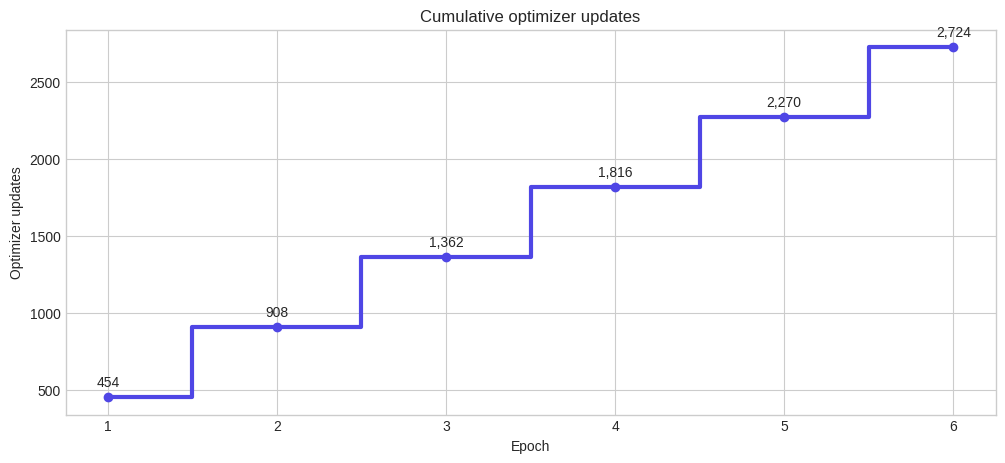

Saved corrected metrics to:
/kaggle/working/phase7_F1_private/plots/f1_epoch_aggregate_metrics.csv


In [23]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Locate the saved private F1 output directory.
OUT = Path("/kaggle/working/phase7_F1_private")
REPORT_PATH = OUT / "F1_report_private.json"

assert REPORT_PATH.is_file(), (
    "F1_report_private.json was not found. "
    "Finish training before running this analysis."
)

# Load aggregate training history only; this does not run inference.
report = json.loads(REPORT_PATH.read_text())
history = report["history"]

assert report["status"] == "complete"
assert report["test_data_used"] is False

# Rebuild the epoch table from the saved report.
rows = []

for item in history:
    validation = item["validation"]

    rows.append({
        "epoch": item["epoch"],
        "training_loss": item["training_loss"],
        "validation_CER_%": 100 * validation["corpus_cer"],
        "S": validation["S"],
        "D": validation["D"],
        "I": validation["I"],
        "EOS_count": validation["eos_count"],
        "cap_without_EOS": validation["cap_without_eos"],
        "U+FFFD": validation["replacement_character_outputs"],
        "epoch_minutes": item["epoch_seconds"] / 60,
        "validation_minutes": validation["elapsed_seconds"] / 60,
        "train_peak_MiB": item["train_peak_allocated_mib"],
        "updates": item.get("updates", 454),
        "cumulative_updates": item.get("cumulative_updates"),
    })

epoch_table = pd.DataFrame(rows)

# Reconstruct cumulative updates if the report did not store them.
if epoch_table["cumulative_updates"].isna().all():
    epoch_table["cumulative_updates"] = (
        epoch_table["updates"].fillna(0).cumsum()
    )
else:
    epoch_table["cumulative_updates"] = (
        epoch_table["cumulative_updates"]
        .fillna(epoch_table["updates"].fillna(0).cumsum())
    )

print("Best epoch:", report["best_epoch"])
print("Final epoch:", int(epoch_table["epoch"].max()))
print("Test data used:", report["test_data_used"])

display(epoch_table.round(3))

# Plot cumulative optimizer updates.
plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(12, 5))

ax.step(
    epoch_table["epoch"],
    epoch_table["cumulative_updates"],
    where="mid",
    linewidth=3,
    marker="o",
    color="#4f46e5",
)

# Add update-count labels above each point.
for epoch, updates in zip(
    epoch_table["epoch"],
    epoch_table["cumulative_updates"],
):
    ax.annotate(
        f"{int(updates):,}",
        (epoch, updates),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
    )

ax.set_title("Cumulative optimizer updates")
ax.set_xlabel("Epoch")
ax.set_ylabel("Optimizer updates")
ax.set_xticks(epoch_table["epoch"])

plt.show()

# Save the corrected aggregate table for later plotting.
plot_dir = OUT / "plots"
plot_dir.mkdir(exist_ok=True)

epoch_table.to_csv(
    plot_dir / "f1_epoch_aggregate_metrics.csv",
    index=False,
)

print("Saved corrected metrics to:")
print(plot_dir / "f1_epoch_aggregate_metrics.csv")

In [25]:
from pathlib import Path
import json
import pandas as pd

# Locate the saved private F1 outputs.
OUT = Path("/kaggle/working/phase7_F1_private")
REPORT_PATH = OUT / "F1_report_private.json"

assert REPORT_PATH.is_file(), (
    "F1_report_private.json was not found. "
    "Finish training before running this cell."
)

# Load aggregate report and epoch history.
report = json.loads(REPORT_PATH.read_text())
history = report["history"]

assert report["status"] == "complete"
assert report["test_data_used"] is False

# Rebuild the epoch table from saved metrics.
rows = []

for item in history:
    validation = item["validation"]

    rows.append({
        "epoch": item["epoch"],
        "training_loss": item["training_loss"],
        "validation_CER_%": 100 * validation["corpus_cer"],
        "S": validation["S"],
        "D": validation["D"],
        "I": validation["I"],
        "EOS_count": validation["eos_count"],
        "cap_without_EOS": validation["cap_without_eos"],
        "U+FFFD": validation["replacement_character_outputs"],
        "epoch_minutes": item["epoch_seconds"] / 60,
        "validation_minutes": validation["elapsed_seconds"] / 60,
        "train_peak_MiB": item["train_peak_allocated_mib"],
        "updates": item.get("updates", 454),
        "cumulative_updates": item.get("cumulative_updates"),
    })

epoch_table = pd.DataFrame(rows)

# Reconstruct cumulative updates if they were not saved.
if epoch_table["cumulative_updates"].isna().all():
    epoch_table["cumulative_updates"] = (
        epoch_table["updates"].fillna(0).cumsum()
    )

# Define the B0 reference and identify the best epoch.
B0_CER = 103.1292389728238

best_row = epoch_table.loc[
    epoch_table["validation_CER_%"].idxmin()
]

best_epoch = int(best_row["epoch"])
final_epoch = int(epoch_table["epoch"].max())

# Create the summary used by the plotting and ZIP cells.
summary = {
    "experiment": "F1",
    "best_epoch": best_epoch,
    "best_validation_cer_percent": float(
        best_row["validation_CER_%"]
    ),
    "final_epoch": final_epoch,
    "final_validation_cer_percent": float(
        epoch_table.loc[
            epoch_table["epoch"] == final_epoch,
            "validation_CER_%"
        ].iloc[0]
    ),
    "B0_cer_percent": B0_CER,
    "improved_over_B0": bool(
        best_row["validation_CER_%"] < B0_CER
    ),
    "test_data_used": False,
}

# Display the important result.
print(json.dumps(summary, indent=2))

# Save aggregate metrics for later plotting.
plot_dir = OUT / "plots"
plot_dir.mkdir(exist_ok=True)

epoch_table.to_csv(
    plot_dir / "f1_epoch_aggregate_metrics.csv",
    index=False,
)

(plot_dir / "f1_plot_summary.json").write_text(
    json.dumps(summary, indent=2) + "\n"
)

print("Saved:")
print(plot_dir / "f1_epoch_aggregate_metrics.csv")
print(plot_dir / "f1_plot_summary.json")

{
  "experiment": "F1",
  "best_epoch": 3,
  "best_validation_cer_percent": 51.346336747899024,
  "final_epoch": 6,
  "final_validation_cer_percent": 55.484353805135875,
  "B0_cer_percent": 103.1292389728238,
  "improved_over_B0": true,
  "test_data_used": false
}
Saved:
/kaggle/working/phase7_F1_private/plots/f1_epoch_aggregate_metrics.csv
/kaggle/working/phase7_F1_private/plots/f1_plot_summary.json


In [26]:
plot_dir = OUT / "plots"
plot_dir.mkdir(exist_ok=True)

# Re-run the figures and save them explicitly if needed.
# This cell saves a compact aggregate table for later plotting without predictions.

epoch_table.to_csv(plot_dir / "f1_epoch_aggregate_metrics.csv", index=False)

summary = {
    "experiment": "F1",
    "best_epoch": best_epoch,
    "best_validation_cer_percent": float(best_row["validation_CER_%"]),
    "B0_cer_percent": B0_CER,
    "improved_over_B0": bool(best_row["validation_CER_%"] < B0_CER),
    "epochs_completed": int(epoch_table["epoch"].max()),
    "test_data_used": False,
}

(plot_dir / "f1_plot_summary.json").write_text(
    json.dumps(summary, indent=2) + "\n"
)

print("Saved aggregate plotting table and summary to:", plot_dir)

Saved aggregate plotting table and summary to: /kaggle/working/phase7_F1_private/plots


In [27]:
# Diagnose possible overfitting conservatively.
best_cer = float(epoch_table['validation_CER_%'].min())
final_cer = float(epoch_table.loc[epoch_table.epoch == final_epoch, 'validation_CER_%'].iloc[0])
best_loss = float(epoch_table.loc[epoch_table.epoch == best_epoch, 'training_loss'].iloc[0])
final_loss = float(epoch_table.loc[epoch_table.epoch == final_epoch, 'training_loss'].iloc[0])
cer_worsened_after_best = final_cer > best_cer
loss_fell_after_best = final_loss < best_loss
if cer_worsened_after_best and loss_fell_after_best:
    diagnosis = 'Possible overfitting: training loss fell after the best validation epoch while validation CER worsened.'
else:
    diagnosis = 'No clear overfitting signal from these aggregate epoch metrics.'
diagnostic = {
    'best_epoch': best_epoch,
    'final_epoch': final_epoch,
    'best_CER_%': best_cer,
    'final_CER_%': final_cer,
    'CER_change_final_minus_best': final_cer - best_cer,
    'best_loss': best_loss,
    'final_loss': final_loss,
    'loss_change_final_minus_best': final_loss - best_loss,
    'diagnosis': diagnosis,
}
print(json.dumps(diagnostic, indent=2))
print('Use the best checkpoint, not the final checkpoint, if validation CER worsened.')


{
  "best_epoch": 3,
  "final_epoch": 6,
  "best_CER_%": 51.346336747899024,
  "final_CER_%": 55.484353805135875,
  "CER_change_final_minus_best": 4.138017057236851,
  "best_loss": 0.9269547315442693,
  "final_loss": 0.5059121210774606,
  "loss_change_final_minus_best": -0.4210426104668087,
  "diagnosis": "Possible overfitting: training loss fell after the best validation epoch while validation CER worsened."
}
Use the best checkpoint, not the final checkpoint, if validation CER worsened.


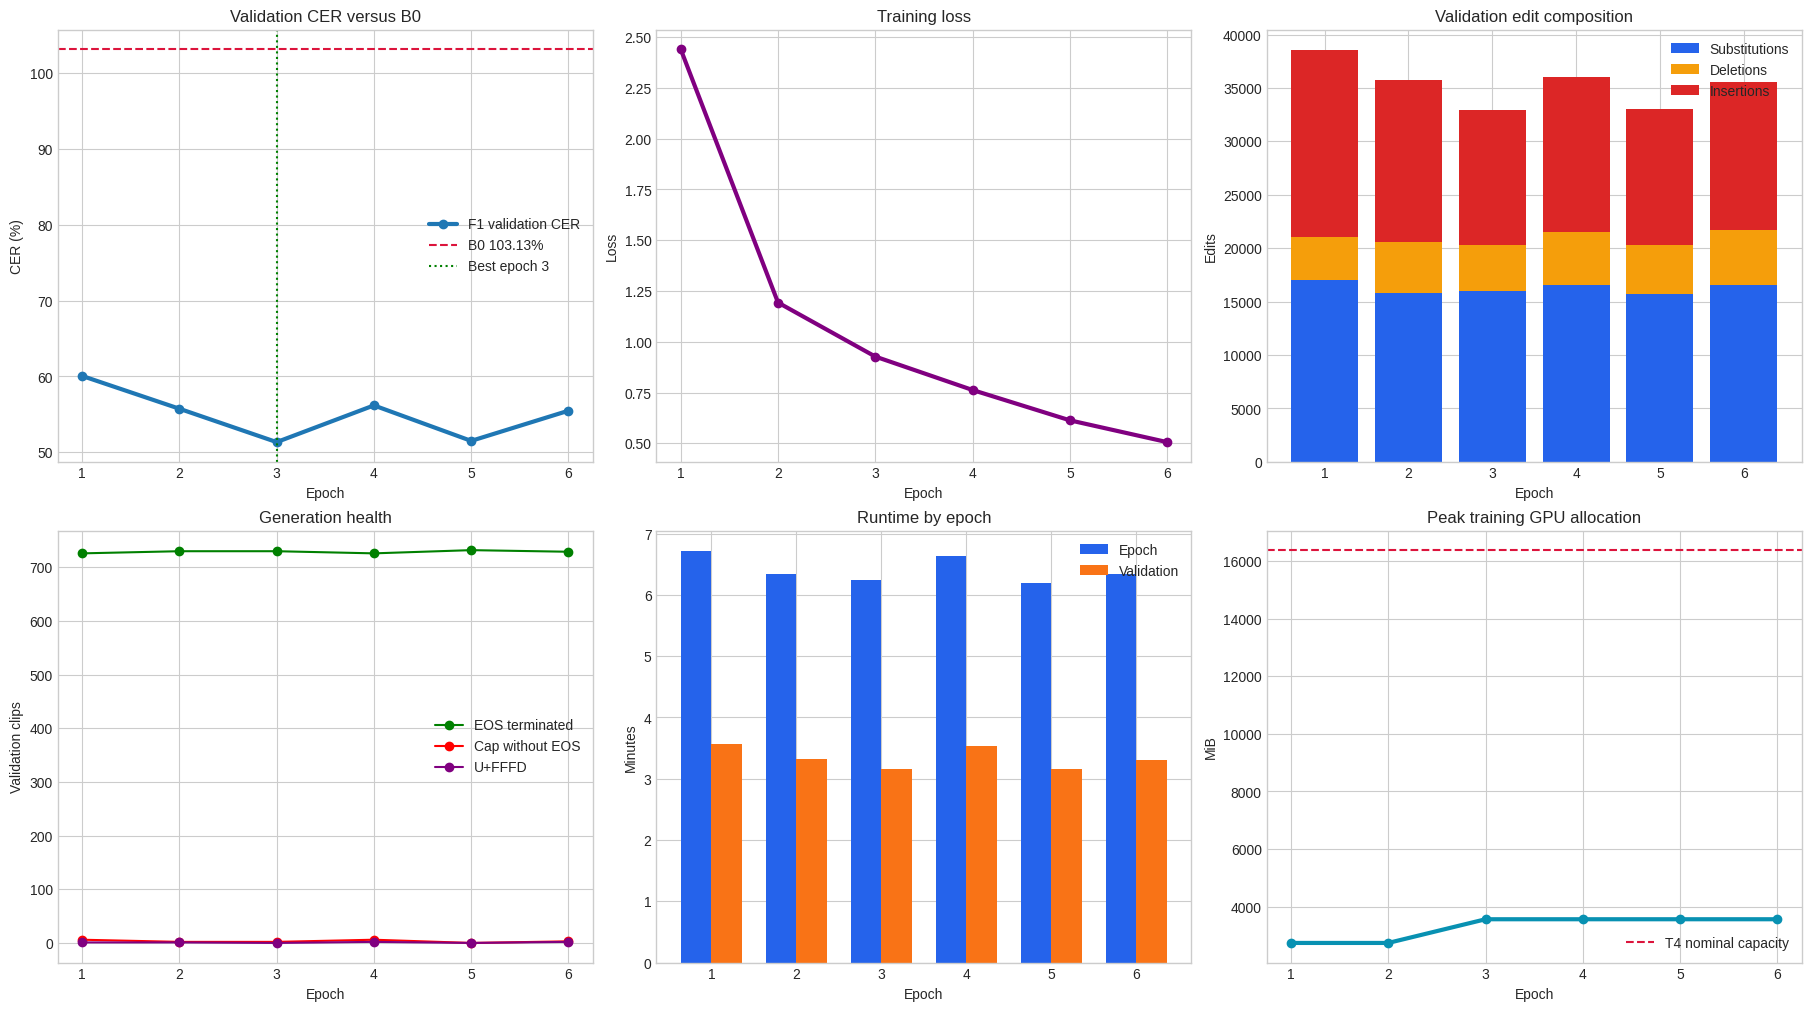

415

In [28]:
# Plot quality, error composition, stopping health, runtime, and memory.
epochs = epoch_table['epoch'].to_numpy()
cer = epoch_table['validation_CER_%'].to_numpy()
loss = epoch_table['training_loss'].to_numpy()
B0_CER = 103.1292389728238
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes[0, 0].plot(epochs, cer, 'o-', lw=3, label='F1 validation CER')
axes[0, 0].axhline(B0_CER, ls='--', color='crimson', label=f'B0 {B0_CER:.2f}%')
axes[0, 0].axvline(best_epoch, ls=':', color='green', label=f'Best epoch {best_epoch}')
axes[0, 0].set(title='Validation CER versus B0', xlabel='Epoch', ylabel='CER (%)')
axes[0, 0].legend()
axes[0, 1].plot(epochs, loss, 'o-', lw=3, color='purple')
axes[0, 1].set(title='Training loss', xlabel='Epoch', ylabel='Loss')
bottom = np.zeros(len(epoch_table))
for key, color, label in [('S', '#2563eb', 'Substitutions'), ('D', '#f59e0b', 'Deletions'), ('I', '#dc2626', 'Insertions')]:
    values = epoch_table[key].to_numpy()
    axes[0, 2].bar(epochs, values, bottom=bottom, color=color, label=label)
    bottom += values
axes[0, 2].set(title='Validation edit composition', xlabel='Epoch', ylabel='Edits')
axes[0, 2].legend()
axes[1, 0].plot(epochs, epoch_table['EOS_count'], 'o-', label='EOS terminated', color='green')
axes[1, 0].plot(epochs, epoch_table['cap_without_EOS'], 'o-', label='Cap without EOS', color='red')
axes[1, 0].plot(epochs, epoch_table['U+FFFD'], 'o-', label='U+FFFD', color='purple')
axes[1, 0].set(title='Generation health', xlabel='Epoch', ylabel='Validation clips')
axes[1, 0].legend()
axes[1, 1].bar(epochs - 0.18, epoch_table['epoch_minutes'], width=.36, label='Epoch', color='#2563eb')
axes[1, 1].bar(epochs + 0.18, epoch_table['validation_minutes'], width=.36, label='Validation', color='#f97316')
axes[1, 1].set(title='Runtime by epoch', xlabel='Epoch', ylabel='Minutes')
axes[1, 1].legend()
axes[1, 2].plot(epochs, epoch_table['train_peak_MiB'], 'o-', lw=3, color='#0891b2')
axes[1, 2].axhline(16 * 1024, ls='--', color='crimson', label='T4 nominal capacity')
axes[1, 2].set(title='Peak training GPU allocation', xlabel='Epoch', ylabel='MiB')
axes[1, 2].legend()
for ax in axes.flat:
    ax.set_xticks(epochs)
plt.show()
(OUT / 'plots').mkdir(exist_ok=True)
epoch_table.to_csv(OUT / 'plots' / 'f1_epoch_aggregate_metrics.csv', index=False)
(OUT / 'plots' / 'f1_overfitting_diagnostic.json').write_text(json.dumps(diagnostic, indent=2) + '\n')


In [29]:
# Package private results and the best checkpoint for download.
best_dir = OUT / f'epoch_{best_epoch:02d}'
assert (best_dir / 'model' / 'config.json').is_file()
assert (best_dir / 'training_state.pt').is_file()
result_files = [OUT / 'F1_report_private.json', OUT / 'aggregate_history.json']
result_files += sorted((OUT / 'plots').glob('*'))
result_files += sorted(OUT.glob('validation_epoch_*_private.jsonl'))
result_files = [p for p in result_files if p.is_file() and '_extracted_inputs' not in p.parts]
result_zip = Path('/kaggle/working/phase7_F1_results_private.zip')
checks = []
with zipfile.ZipFile(result_zip, 'w', zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True) as z:
    for path in tqdm(result_files, desc='Zipping private results', unit='file'):
        arc = f'phase7_F1_results/{path.relative_to(OUT).as_posix()}'
        z.write(path, arc)
        checks.append(f"{hashlib.sha256(path.read_bytes()).hexdigest()}  {arc}")
    z.writestr('phase7_F1_results/SHA256SUMS.txt', '\n'.join(checks) + '\n')
checkpoint_zip = Path('/kaggle/working/phase7_F1_best_checkpoint_private.zip')
with zipfile.ZipFile(checkpoint_zip, 'w', zipfile.ZIP_STORED, allowZip64=True) as z:
    for path in tqdm([p for p in best_dir.rglob('*') if p.is_file()], desc='Zipping best checkpoint', unit='file'):
        z.write(path, f'phase7_F1_best_checkpoint/{path.relative_to(best_dir).as_posix()}')
assert zipfile.ZipFile(result_zip).testzip() is None
assert zipfile.ZipFile(checkpoint_zip).testzip() is None
print('Results:', result_zip, round(result_zip.stat().st_size / 1024**2, 2), 'MiB')
print('Checkpoint:', checkpoint_zip, round(checkpoint_zip.stat().st_size / 1024**2, 2), 'MiB')
display(FileLink(str(result_zip)))
display(FileLink(str(checkpoint_zip)))


Zipping private results:   0%|          | 0/11 [00:00<?, ?file/s]

Zipping best checkpoint:   0%|          | 0/4 [00:00<?, ?file/s]

Results: /kaggle/working/phase7_F1_results_private.zip 0.9 MiB
Checkpoint: /kaggle/working/phase7_F1_best_checkpoint_private.zip 825.16 MiB


/kaggle/working/phase7_F1_results_private.zip

/kaggle/working/phase7_F1_best_checkpoint_private.zip

In [30]:
from pathlib import Path
import copy
import csv
import json
import re
import time
import unicodedata
import zipfile

import numpy as np
import pandas as pd
import soundfile as sf
import torch
from tqdm.auto import tqdm
from transformers import (
    GenerationConfig,
    WhisperForConditionalGeneration,
    WhisperProcessor,
)

# Private Kaggle paths.
WORK = Path("/kaggle/working")
F1_OUT = WORK / "phase7_F1_private"

assert F1_OUT.is_dir(), "F1 output directory not found."

# The best checkpoint is Epoch 3.
BEST_EPOCH = 3
CHECKPOINT_DIR = F1_OUT / f"epoch_{BEST_EPOCH:02d}"

assert (CHECKPOINT_DIR / "model" / "config.json").is_file()
assert (CHECKPOINT_DIR / "training_state.pt").is_file()

# Locate the private validation bundle.
input_root = Path("/kaggle/input")

validation_candidates = list(
    input_root.rglob("phase5_validation_bundle.zip")
)

if not validation_candidates:
    validation_candidates = list(
        input_root.rglob("*validation*")
    )

assert validation_candidates, "Attach the private Phase 5 validation bundle."

validation_input = validation_candidates[0]
print("Checkpoint:", CHECKPOINT_DIR)
print("Validation input:", validation_input)

Checkpoint: /kaggle/working/phase7_F1_private/epoch_03
Validation input: /kaggle/input/datasets/kanchanpotdar/phase5-validation-bundle


In [32]:
# Extract the private validation bundle if Kaggle mounted it as a ZIP.
EXTRACTED = WORK / "phase7_validation_audit_inputs"
EXTRACTED.mkdir(exist_ok=True)

if validation_input.is_file() and validation_input.suffix == ".zip":
    with zipfile.ZipFile(validation_input) as zf:
        marker = next(
            name for name in zf.namelist()
            if name.endswith("bundle_record.json")
        )

        record = json.loads(zf.read(marker))
        validation_root = EXTRACTED / "phase5_validation_baseline"
        validation_root.mkdir(parents=True, exist_ok=True)

        for member in tqdm(
            zf.infolist(),
            desc="Extracting validation bundle",
            unit="file",
        ):
            zf.extract(member, validation_root)

        validation_root = (
            validation_root / Path(marker).parent
        ).resolve()
else:
    validation_root = validation_input

# Load validation rows.
with (validation_root / "validation_manifest.csv").open(
    newline="",
    encoding="utf-8",
) as stream:
    validation_rows = list(csv.DictReader(stream))

assert len(validation_rows) == 732
assert sum(len(row["reference"]) for row in validation_rows) == 64137

# Approved NFD normalization.
def normalize(value):
    return re.sub(
        r" {2,}",
        " ",
        unicodedata.normalize("NFD", str(value)).strip(),
    )

# Character-level S/D/I calculation.
def edit_counts(reference, hypothesis):
    ref = list(reference)
    hyp = list(hypothesis)

    distance = [
        [0] * (len(hyp) + 1)
        for _ in range(len(ref) + 1)
    ]

    for i in range(len(ref) + 1):
        distance[i][0] = i

    for j in range(len(hyp) + 1):
        distance[0][j] = j

    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):
            distance[i][j] = min(
                distance[i - 1][j] + 1,
                distance[i][j - 1] + 1,
                distance[i - 1][j - 1]
                + (ref[i - 1] != hyp[j - 1]),
            )

    substitutions = deletions = insertions = 0
    i, j = len(ref), len(hyp)

    while i or j:
        if (
            i
            and j
            and ref[i - 1] == hyp[j - 1]
            and distance[i][j] == distance[i - 1][j - 1]
        ):
            i -= 1
            j -= 1
        elif (
            i
            and j
            and distance[i][j]
            == distance[i - 1][j - 1] + 1
        ):
            substitutions += 1
            i -= 1
            j -= 1
        elif i and distance[i][j] == distance[i - 1][j] + 1:
            deletions += 1
            i -= 1
        else:
            insertions += 1
            j -= 1

    return substitutions, deletions, insertions

In [33]:
# Load the processor and Epoch 3 model.
MODEL_ID = "neurlang/ipa-whisper-base"
MODEL_REVISION = (
    "949f7c4e4ee374b5202bc5886f6e4552e5ae2371"
)

processor = WhisperProcessor.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
)

model = WhisperForConditionalGeneration.from_pretrained(
    CHECKPOINT_DIR / "model",
    dtype=torch.float32,
    attn_implementation="sdpa",
).cuda().eval()

# Remove deprecated forced-decoder configuration.
model.config.forced_decoder_ids = None
model.generation_config.forced_decoder_ids = None

generation_config = GenerationConfig.from_dict(
    json.loads(
        (validation_root / "generation_config.json").read_text()
    )
)

# Corrected, explicit policy:
# automatic language detection + transcription task.
generation_config.forced_decoder_ids = None
generation_config.language = None
generation_config.task = "transcribe"
generation_config.suppress_tokens = []
generation_config.begin_suppress_tokens = [220, 50257]
generation_config.do_sample = False
generation_config.num_beams = 1
generation_config.max_length = 448
generation_config.return_dict_in_generate = True

def read_audio(row):
    audio, sample_rate = sf.read(
        validation_root / row["audio_file"],
        dtype="float32",
        always_2d=True,
    )

    assert sample_rate == 16000
    assert audio.shape[1] == 1

    return audio[:, 0]

def make_features(rows):
    audios = [read_audio(row) for row in rows]

    encoded = processor.feature_extractor(
        audios,
        sampling_rate=16000,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        max_length=480000,
        return_attention_mask=True,
    )

    features = encoded.input_features
    attention_mask = encoded.attention_mask

    # Defensive fixed Whisper window normalization.
    if features.shape[-1] > 3000:
        features = features[..., :3000]
    elif features.shape[-1] < 3000:
        features = torch.nn.functional.pad(
            features,
            (0, 3000 - features.shape[-1]),
        )

    assert tuple(features.shape[1:]) == (80, 3000)
    assert torch.isfinite(features).all()

    return features.float().cuda(), attention_mask.cuda()

def evaluate_generation(config, output_name):
    records = []
    started = time.perf_counter()

    for begin in tqdm(
        range(0, len(validation_rows), 8),
        desc=output_name,
        unit="batch",
    ):
        rows = validation_rows[begin:begin + 8]
        features, attention_mask = make_features(rows)

        with torch.inference_mode():
            output = model.generate(
                input_features=features,
                attention_mask=attention_mask,
                generation_config=copy.deepcopy(config),
            )

        for row, sequence in zip(
            rows,
            output.sequences.detach().cpu().tolist(),
        ):
            ids = (
                sequence[:sequence.index(50257) + 1]
                if 50257 in sequence
                else sequence[:448]
            )

            raw = processor.tokenizer.decode(
                ids,
                skip_special_tokens=True,
            )

            hypothesis = normalize(raw)
            reference = normalize(row["reference"])

            substitutions, deletions, insertions = edit_counts(
                reference,
                hypothesis,
            )

            records.append({
                "sample_id": row["sample_id"],
                "reference": reference,
                "prediction": hypothesis,
                "S": substitutions,
                "D": deletions,
                "I": insertions,
                "eos": bool(ids and ids[-1] == 50257),
                "cap_without_eos": (
                    len(ids) >= 448
                    and (not ids or ids[-1] != 50257)
                ),
                "duration_seconds": float(
                    row["duration_seconds"]
                ),
            })

    reference_chars = sum(
        len(item["reference"])
        for item in records
    )

    S = sum(item["S"] for item in records)
    D = sum(item["D"] for item in records)
    I = sum(item["I"] for item in records)

    metrics = {
        "clips": len(records),
        "reference_codepoints": reference_chars,
        "S": S,
        "D": D,
        "I": I,
        "edit_count": S + D + I,
        "corpus_cer_percent": 100 * (S + D + I) / reference_chars,
        "eos_count": sum(item["eos"] for item in records),
        "cap_without_eos": sum(
            item["cap_without_eos"]
            for item in records
        ),
        "elapsed_seconds": time.perf_counter() - started,
    }

    output_path = F1_OUT / output_name
    output_path.write_text(
        "\n".join(
            json.dumps(item, ensure_ascii=False)
            for item in records
        )
        + "\n"
    )

    return metrics, records

corrected_metrics, corrected_predictions = evaluate_generation(
    generation_config,
    "epoch_03_corrected_predictions_private.jsonl",
)

print(json.dumps(corrected_metrics, indent=2))

epoch_03_corrected_predictions_private.jsonl:   0%|          | 0/92 [00:00<?, ?batch/s]

{
  "clips": 732,
  "reference_codepoints": 64137,
  "S": 15940,
  "D": 4323,
  "I": 12669,
  "edit_count": 32932,
  "corpus_cer_percent": 51.34633674789903,
  "eos_count": 730,
  "cap_without_eos": 2,
  "elapsed_seconds": 177.0129805179995
}


In [34]:
# Load the original Epoch 3 predictions from the F1 results ZIP.
original_predictions = []

with zipfile.ZipFile("/kaggle/working/phase7_F1_results_private.zip") as zf:
    candidates = [
        name for name in zf.namelist()
        if "validation_epoch_03_private.jsonl" in name
    ]

    assert candidates, "Original Epoch 3 predictions not found."

    for line in zf.read(candidates[0]).decode().splitlines():
        if line.strip():
            original_predictions.append(json.loads(line))

assert len(original_predictions) == 732
assert len(corrected_predictions) == 732

comparison = []

for old, new in zip(
    original_predictions,
    corrected_predictions,
):
    old_prediction = old.get(
        "normalized_prediction",
        old.get("prediction", old.get("hypothesis", "")),
    )

    new_prediction = new["prediction"]

    comparison.append({
        "sample_id": new["sample_id"],
        "same_prediction": old_prediction == new_prediction,
        "old_prediction": old_prediction,
        "corrected_prediction": new_prediction,
    })

comparison_table = pd.DataFrame(comparison)

print(
    "Identical predictions:",
    int(comparison_table["same_prediction"].sum()),
    "/",
    len(comparison_table),
)

display(
    comparison_table[
        ~comparison_table["same_prediction"]
    ].head(20)
)

Identical predictions: 732 / 732


,sample_id,same_prediction,old_prediction,corrected_prediction


In [35]:
# Rank the corrected validation examples by insertion count.
diagnostics = pd.DataFrame(corrected_predictions)

diagnostics["CER_%"] = 100 * (
    diagnostics["S"]
    + diagnostics["D"]
    + diagnostics["I"]
) / diagnostics["reference"].str.len().clip(lower=1)

diagnostics["reference_length"] = (
    diagnostics["reference"].str.len()
)

diagnostics["prediction_length"] = (
    diagnostics["prediction"].str.len()
)

diagnostics["length_ratio"] = (
    diagnostics["prediction_length"]
    / diagnostics["reference_length"].clip(lower=1)
)

# Most insertion-heavy examples.
top_insertions = diagnostics.sort_values(
    ["I", "length_ratio"],
    ascending=False,
)

display(
    top_insertions[
        [
            "sample_id",
            "duration_seconds",
            "reference",
            "prediction",
            "CER_%",
            "S",
            "D",
            "I",
            "eos",
            "cap_without_eos",
            "length_ratio",
        ]
    ].head(25)
)

,sample_id,duration_seconds,reference,prediction,CER_%,S,D,I,eos,cap_without_eos,length_ratio
241,A_001560,24.12,roŋo palajel saca sacaŋe doden sacae doke saca...,roŋupəlaːlʌ paːlaːlaːjel sɯca səca səcaː nɯdod...,98.936170,40,0,146,True,False,1.776596
242,A_001562,26.50,molɡe oso niɡaŋe mul sora ɲora xiru uilkəm ɲor...,mul gəb ho so ɲigangəm ŋul soara ɲora kiru ilk...,93.063584,44,2,115,True,False,1.653179
688,A_006234,28.26,heŋulɡe ɲaɡaŋe simabe simulɡe sam siɟa tukaŋe ...,he mulge ɲega nega nɛ ɲega nɛ cima simul simul...,88.461538,49,0,112,True,False,1.615385
639,A_005222,18.52,mulɡe nisi nijemɡe eke nisiɟikəm mulɡe he mulɡ...,o mulge nisi nijisi nijemge haki nisi ɲisi ɲia...,100.621118,55,0,107,True,False,1.664596
632,A_005189,25.55,kulɡe mul t̪apo namama t̪apo ɟaŋulte jaculi to...,kul gə ŋul t̪aponaməm məməm ben t̪apoɯɟəm ŋul ...,68.273092,57,9,104,True,False,1.381526
687,A_006233,26.38,he ŋul siɟa siɟa tuɡe akin akin madkonai nakin...,he mul siɟa siɟa tuɯɡe akin akin matkunai akin...,66.945607,53,14,93,True,False,1.330544
626,A_005179,21.62,hocinəm amamul kuluɡ kuluɡ nijem ɡalokəmto mul...,o cenam ɨnam amam amam ŋul kulu kulu kulu niam...,114.130435,15,2,88,True,False,1.934783
663,A_006172,29.81,hoɡe aken medikl helikam mule praiməri helt se...,nam hoɯga akam mɛdikiːkile heikam mule praimer...,43.034826,68,18,87,True,False,1.171642
638,A_005221,10.20,mɛməriŋa doro,meːməriŋə doru ɖo ho kɨjin biːkɨŋəm biː biːbɪk...,661.538462,2,0,84,True,False,7.461538
128,A_001100,29.99,primari ŋo pori kuje te soŋram aɲi boram skul ...,əʊmʌmʌriːmʌriːʌʌʊŋo poriː kue t̪e səŋəram ane ...,116.101695,191,1,82,False,True,1.343220


In [36]:
# These are validation-only decoding experiments.
# Do not replace the primary evaluation policy silently.
ablations = {
    "corrected_primary": {
        "repetition_penalty": 1.0,
        "no_repeat_ngram_size": 0,
    },
    "mild_repetition_penalty": {
        "repetition_penalty": 1.05,
        "no_repeat_ngram_size": 0,
    },
    "limited_no_repeat_3gram": {
        "repetition_penalty": 1.0,
        "no_repeat_ngram_size": 3,
    },
}

ablation_results = []

for name, settings in ablations.items():
    config = copy.deepcopy(generation_config)

    config.repetition_penalty = settings[
        "repetition_penalty"
    ]

    config.no_repeat_ngram_size = settings[
        "no_repeat_ngram_size"
    ]

    metrics, predictions = evaluate_generation(
        config,
        f"epoch_03_{name}_predictions_private.jsonl",
    )

    metrics["configuration"] = name
    metrics.update(settings)
    ablation_results.append(metrics)

ablation_table = pd.DataFrame(ablation_results)

display(
    ablation_table[
        [
            "configuration",
            "corpus_cer_percent",
            "S",
            "D",
            "I",
            "eos_count",
            "cap_without_eos",
            "elapsed_seconds",
        ]
    ].sort_values("corpus_cer_percent")
)

epoch_03_corrected_primary_predictions_private.jsonl:   0%|          | 0/92 [00:00<?, ?batch/s]

epoch_03_mild_repetition_penalty_predictions_private.jsonl:   0%|          | 0/92 [00:00<?, ?batch/s]

epoch_03_limited_no_repeat_3gram_predictions_private.jsonl:   0%|          | 0/92 [00:00<?, ?batch/s]

,configuration,corpus_cer_percent,S,D,I,eos_count,cap_without_eos,elapsed_seconds
1,mild_repetition_penalty,48.549199,14785,5236,11117,732,0,165.089041
0,corrected_primary,51.346337,15940,4323,12669,730,2,176.711937
2,limited_no_repeat_3gram,52.997490,16391,4655,12945,732,0,195.946098


In [37]:
from pathlib import Path
import hashlib
import json
import zipfile
from tqdm.auto import tqdm
from IPython.display import FileLink, display

# Private output directory for the corrected validation audit.
AUDIT_OUT = F1_OUT / "epoch_03_validation_audit_private"
AUDIT_OUT.mkdir(parents=True, exist_ok=True)

# Save corrected primary metrics.
(AUDIT_OUT / "corrected_epoch_03_metrics.json").write_text(
    json.dumps(corrected_metrics, indent=2) + "\n"
)

# Save corrected primary predictions.
(AUDIT_OUT / "corrected_epoch_03_predictions_private.jsonl").write_text(
    "\n".join(
        json.dumps(item, ensure_ascii=False)
        for item in corrected_predictions
    )
    + "\n"
)

# Save original-versus-corrected comparison.
comparison_table.to_json(
    AUDIT_OUT / "original_vs_corrected_comparison_private.json",
    orient="records",
    force_ascii=False,
    indent=2,
)

# Save insertion diagnostics.
diagnostics.to_json(
    AUDIT_OUT / "corrected_insertion_diagnostics_private.json",
    orient="records",
    force_ascii=False,
    indent=2,
)

# Save decoding-ablation results if the ablation cell was run.
if "ablation_table" in globals():
    ablation_table.to_csv(
        AUDIT_OUT / "decoding_ablation_metrics_private.csv",
        index=False,
    )

    ablation_table.to_json(
        AUDIT_OUT / "decoding_ablation_metrics_private.json",
        orient="records",
        indent=2,
    )

# Save the exact effective generation configuration.
(AUDIT_OUT / "corrected_generation_config.json").write_text(
    json.dumps(
        generation_config.to_dict(),
        indent=2,
        default=str,
    )
    + "\n"
)

# Save a compact audit summary.
summary = {
    "checkpoint": "F1 Epoch 3",
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "validation_clips": corrected_metrics["clips"],
    "reference_codepoints": corrected_metrics[
        "reference_codepoints"
    ],
    "corrected_cer_percent": corrected_metrics[
        "corpus_cer_percent"
    ],
    "test_data_used": False,
    "attention_mask_supplied": True,
    "task": "transcribe",
    "language": None,
    "forced_decoder_ids": None,
    "primary_policy_changed": False,
}

(AUDIT_OUT / "validation_audit_summary.json").write_text(
    json.dumps(summary, indent=2) + "\n"
)

# Create one private ZIP containing the audit artifacts.
audit_zip = Path(
    "/kaggle/working/phase7_epoch03_validation_audit_private.zip"
)

audit_files = [
    path for path in AUDIT_OUT.rglob("*")
    if path.is_file()
]

checksums = []

with zipfile.ZipFile(
    audit_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True,
) as archive:
    for path in tqdm(
        audit_files,
        desc="Zipping validation audit",
        unit="file",
    ):
        archive_name = (
            "phase7_epoch03_validation_audit/"
            + path.relative_to(AUDIT_OUT).as_posix()
        )

        archive.write(path, archive_name)

        digest = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        checksums.append(
            f"{digest}  {archive_name}"
        )

    archive.writestr(
        "phase7_epoch03_validation_audit/SHA256SUMS.txt",
        "\n".join(checksums) + "\n",
    )

# Verify the ZIP before downloading.
with zipfile.ZipFile(audit_zip) as archive:
    assert archive.testzip() is None

print("Saved private audit directory:")
print(AUDIT_OUT)

print("\nSaved private audit ZIP:")
print(audit_zip)
print("Size MiB:", round(audit_zip.stat().st_size / 1024**2, 2))

display(FileLink(str(audit_zip)))

Zipping validation audit:   0%|          | 0/8 [00:00<?, ?file/s]

Saved private audit directory:
/kaggle/working/phase7_F1_private/epoch_03_validation_audit_private

Saved private audit ZIP:
/kaggle/working/phase7_epoch03_validation_audit_private.zip
Size MiB: 0.22


/kaggle/working/phase7_epoch03_validation_audit_private.zip

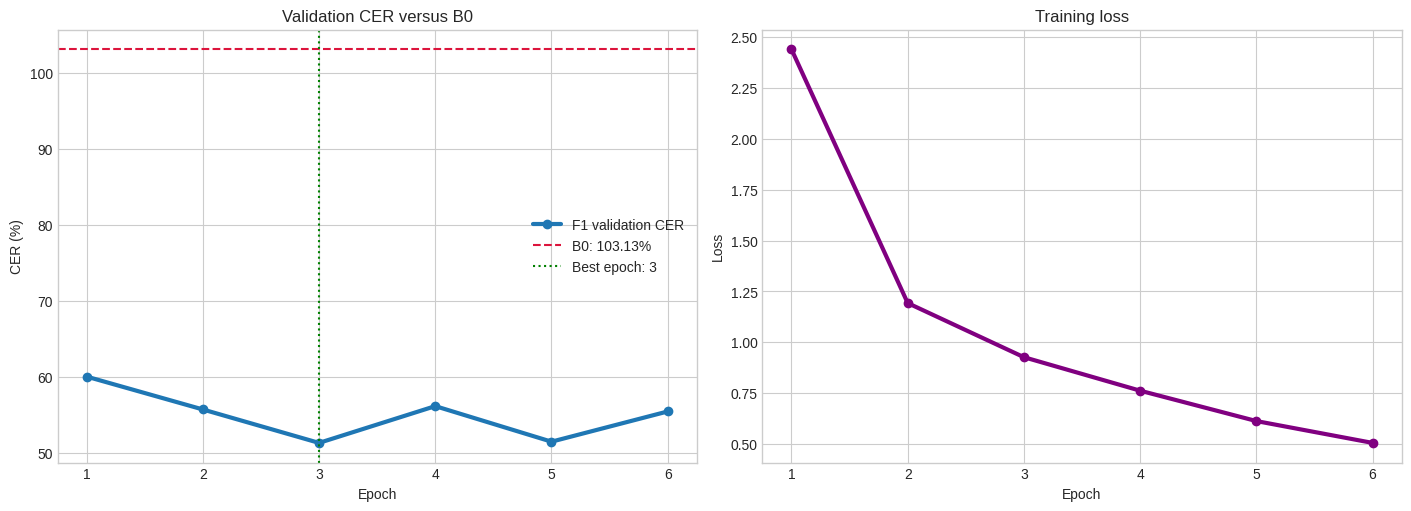

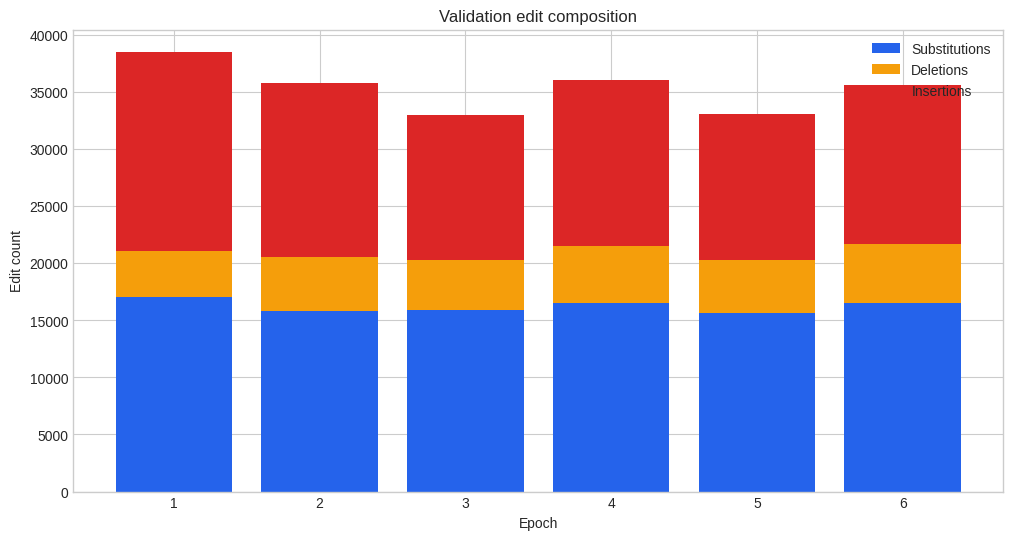

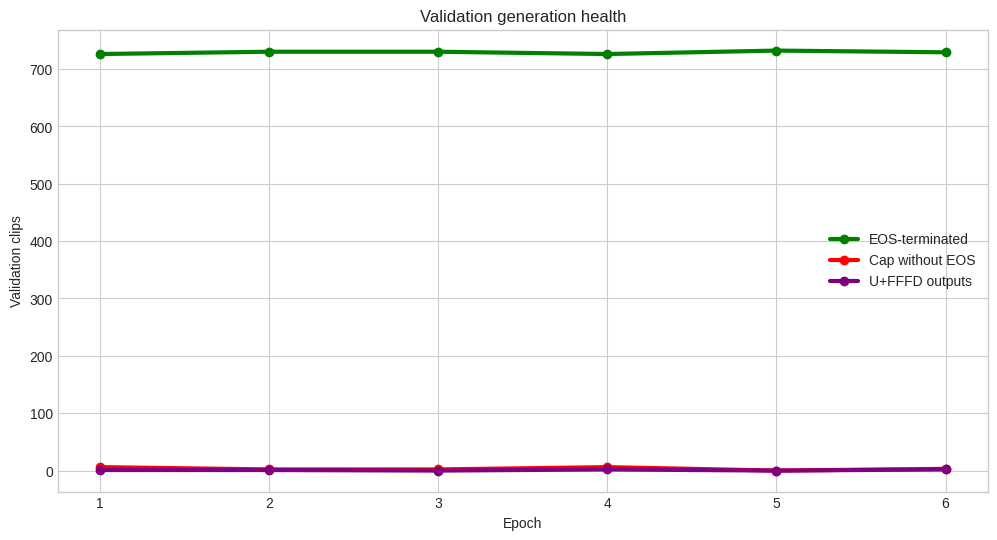

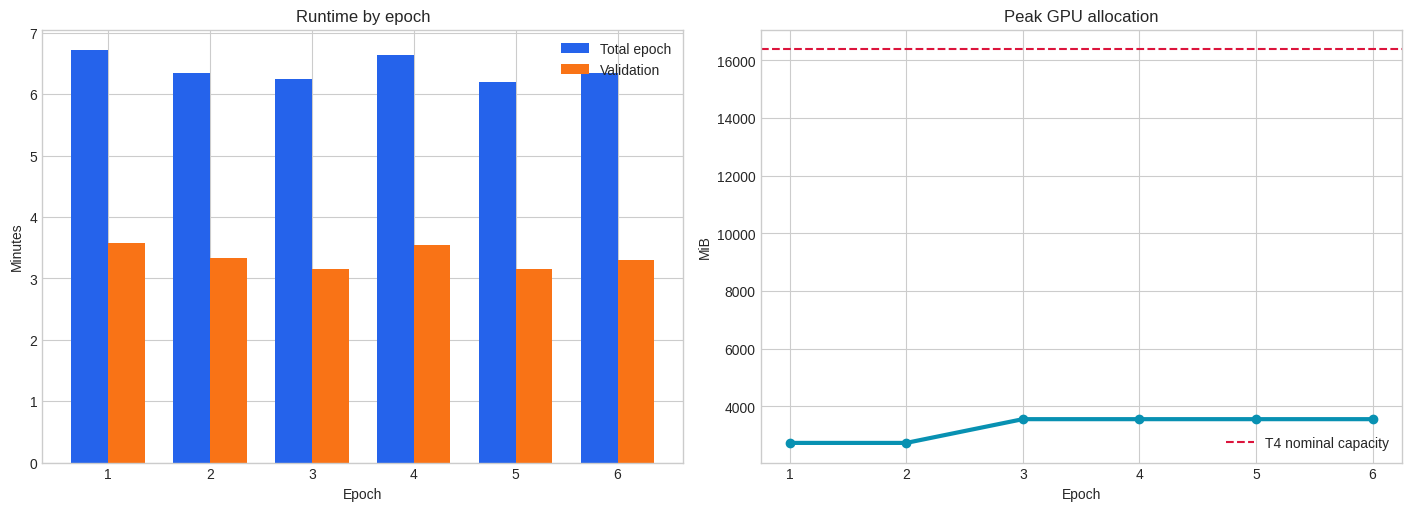

Zipping plots:   0%|          | 0/6 [00:00<?, ?file/s]

Saved plots to: /kaggle/working/phase7_F1_private/saved_plots_private
Created ZIP: /kaggle/working/phase7_F1_plots_private.zip
ZIP size MiB: 0.21


/kaggle/working/phase7_F1_plots_private.zip

In [38]:
from pathlib import Path
import json
import zipfile
from tqdm.auto import tqdm
from IPython.display import FileLink, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate saved F1 outputs.
OUT = Path("/kaggle/working/phase7_F1_private")
REPORT = OUT / "F1_report_private.json"

assert REPORT.is_file(), "F1_report_private.json was not found."

# Load aggregate epoch history.
report = json.loads(REPORT.read_text())
history = report["history"]

rows = []

for item in history:
    val = item["validation"]

    rows.append({
        "epoch": item["epoch"],
        "training_loss": item["training_loss"],
        "CER_%": 100 * val["corpus_cer"],
        "S": val["S"],
        "D": val["D"],
        "I": val["I"],
        "EOS": val["eos_count"],
        "cap_without_EOS": val["cap_without_eos"],
        "U+FFFD": val["replacement_character_outputs"],
        "epoch_minutes": item["epoch_seconds"] / 60,
        "validation_minutes": val["elapsed_seconds"] / 60,
        "train_peak_MiB": item["train_peak_allocated_mib"],
    })

table = pd.DataFrame(rows)
epochs = table["epoch"].to_numpy()
best_epoch = int(report["best_epoch"])
B0_CER = 103.1292389728238

# Private plot directory.
PLOT_DIR = OUT / "saved_plots_private"
PLOT_DIR.mkdir(exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")

# 1. CER and training loss.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

axes[0].plot(
    epochs,
    table["CER_%"],
    "o-",
    linewidth=3,
    label="F1 validation CER",
)

axes[0].axhline(
    B0_CER,
    linestyle="--",
    color="crimson",
    label=f"B0: {B0_CER:.2f}%",
)

axes[0].axvline(
    best_epoch,
    linestyle=":",
    color="green",
    label=f"Best epoch: {best_epoch}",
)

axes[0].set_title("Validation CER versus B0")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("CER (%)")
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    table["training_loss"],
    "o-",
    linewidth=3,
    color="purple",
)

axes[1].set_title("Training loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(epochs)

fig.savefig(
    PLOT_DIR / "01_f1_cer_and_training_loss.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# 2. Error composition.
fig, ax = plt.subplots(figsize=(12, 6))

bottom = np.zeros(len(table))

for key, color, label in [
    ("S", "#2563eb", "Substitutions"),
    ("D", "#f59e0b", "Deletions"),
    ("I", "#dc2626", "Insertions"),
]:
    values = table[key].to_numpy()

    ax.bar(
        epochs,
        values,
        bottom=bottom,
        color=color,
        label=label,
    )

    bottom += values

ax.set_title("Validation edit composition")
ax.set_xlabel("Epoch")
ax.set_ylabel("Edit count")
ax.set_xticks(epochs)
ax.legend()

fig.savefig(
    PLOT_DIR / "02_validation_edit_composition.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# 3. Generation health.
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    epochs,
    table["EOS"],
    "o-",
    linewidth=3,
    color="green",
    label="EOS-terminated",
)

ax.plot(
    epochs,
    table["cap_without_EOS"],
    "o-",
    linewidth=3,
    color="red",
    label="Cap without EOS",
)

ax.plot(
    epochs,
    table["U+FFFD"],
    "o-",
    linewidth=3,
    color="purple",
    label="U+FFFD outputs",
)

ax.set_title("Validation generation health")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation clips")
ax.set_xticks(epochs)
ax.legend()

fig.savefig(
    PLOT_DIR / "03_generation_health.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# 4. Runtime and memory.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

axes[0].bar(
    epochs - 0.18,
    table["epoch_minutes"],
    width=0.36,
    label="Total epoch",
    color="#2563eb",
)

axes[0].bar(
    epochs + 0.18,
    table["validation_minutes"],
    width=0.36,
    label="Validation",
    color="#f97316",
)

axes[0].set_title("Runtime by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Minutes")
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    table["train_peak_MiB"],
    "o-",
    linewidth=3,
    color="#0891b2",
)

axes[1].axhline(
    16 * 1024,
    linestyle="--",
    color="crimson",
    label="T4 nominal capacity",
)

axes[1].set_title("Peak GPU allocation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MiB")
axes[1].set_xticks(epochs)
axes[1].legend()

fig.savefig(
    PLOT_DIR / "04_runtime_and_gpu_memory.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# 5. Save aggregate data used for plots.
table.to_csv(
    PLOT_DIR / "f1_epoch_plot_data.csv",
    index=False,
)

summary = {
    "best_epoch": best_epoch,
    "best_CER_percent": float(table["CER_%"].min()),
    "B0_CER_percent": B0_CER,
    "test_data_used": False,
}

(PLOT_DIR / "plot_summary.json").write_text(
    json.dumps(summary, indent=2) + "\n"
)

# Create a separate private plots ZIP.
PLOTS_ZIP = Path(
    "/kaggle/working/phase7_F1_plots_private.zip"
)

plot_files = sorted(
    p for p in PLOT_DIR.iterdir()
    if p.is_file()
)

with zipfile.ZipFile(
    PLOTS_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
) as archive:
    for path in tqdm(
        plot_files,
        desc="Zipping plots",
        unit="file",
    ):
        archive.write(
            path,
            f"phase7_F1_plots/{path.name}",
        )

with zipfile.ZipFile(PLOTS_ZIP) as archive:
    assert archive.testzip() is None

print("Saved plots to:", PLOT_DIR)
print("Created ZIP:", PLOTS_ZIP)
print("ZIP size MiB:", round(PLOTS_ZIP.stat().st_size / 1024**2, 2))

display(FileLink(str(PLOTS_ZIP)))